# Classical Reasoning Agent: Logical Entailment from Natural Language

**Pipeline:** natural-language knowledge base → spaCy-assisted semantic parser → facts / rules / FOL clauses / causal model → classical reasoning engine → `True` / `False`

| Input kind (auto-detected) | Representation | Reasoning engine |
|---|---|---|
| Simple facts + if-then rules (RuleTaker style) | Function-free Horn clauses with negation | Stratified **forward chaining** with **unification** and negation-as-failure (closed world) |
| General first-order logic (FOLIO style, NL or formulas) | Clausal normal form (CNF) | **Resolution refutation** with unification, set-of-support, unit preference, factoring |
| Causal statements + counterfactual questions (CounterBench style) | Boolean structural causal model (SCM) | Abduction → intervention (`do`) → **forward propagation**, exhaustive search over exogenous worlds |

No generative model is used anywhere. spaCy is used only for tokenisation, lemmatisation and dependency parsing.

## Setup and configuration

In [1]:
import heapq
import itertools
import json
import os
import random
import re
import time
import urllib.request
from collections import Counter, defaultdict

import pandas as pd

CONFIG = {
    'TEST_PATH': 'test.csv',  # private test file (csv / json / jsonl / parquet); public data is used if missing
    'RUN_EXPERIMENTS': True,  # False = fast run: skip public-data experiments, only predict TEST_PATH
    'OUT_PATH': 'submission.csv',
    'RULETAKER_LIMIT': None,  # None = full splits; an int gives a random sample for quick runs
    'SEED': 0,
    'RES_MAX_STEPS': 2000,  # resolvents per proof attempt (deterministic budget; proofs on FOLIO train need <= 26)
    'RES_TIME_LIMIT': 2.0,  # wall-clock safety net per proof, in seconds
    'RES_MAX_CLAUSES': 3000,
    'RES_MAX_LITERALS': 8,
    'CNF_MAX_CLAUSES': 64,  # per formula
    'RES_UNIT_SUBSUMPTION': True,  # discard resolvents subsumed by a unit clause (ablation switch)
    'FIG_DIR': os.path.expanduser(
        '~/.cache/reasoning_agent/figures'
    ),  # where the experiment figures are saved
}

# Two spaCy pipelines from the same model: a light one (tagger + lemmatiser) for the Horn grammar, and one with
# the dependency parser for the free-form FOL translator. Without spaCy the Horn grammar falls back to a
# rule-based lemmatiser and the free-form translator is disabled (see README.txt for installation).
try:
    import spacy

    NLP = spacy.load('en_core_web_sm', disable=['parser', 'ner'])
    NLP_DEP = spacy.load('en_core_web_sm', disable=['ner'])
except (ImportError, OSError) as e:
    print('spaCy or en_core_web_sm not available:', e)
    print('Install with: pip install spacy && python -m spacy download en_core_web_sm')
    NLP = NLP_DEP = None
print('spaCy model loaded:', NLP is not None)

spaCy model loaded: True


# Part 1 — Internal representation and natural-language parsing

### 1.1 Data structures

* **Terms**: constants are lowercase strings (`bob`, `bald_eagle`); variables start with `?` (`?x`); Skolem terms are tuples `('sk', name, args...)`.
* **Literal**: `(positive: bool, predicate: str, args: tuple)`, e.g. `(True, 'kind', ('bob',))` = Kind(bob), `(False, 'see', ('cat','dog'))` = ¬See(cat, dog).
* **Horn rule**: `Rule(body=[literals], head=literal)`; negative body literals are read with negation-as-failure.
* **FOL formula**: nested tuples `('all', v, F)`, `('ex', v, F)`, `('and', A, B)`, `('or', A, B)`, `('imp', A, B)`, `('iff', A, B)`, `('xor', A, B)`, `('not', F)`, `('atom', pred, args)`.
* **Clause**: `frozenset` of literals (for resolution).

In [2]:
class Rule:
    __slots__ = ('body', 'head', 'text')

    def __init__(self, body, head, text=''):
        self.body = list(body)
        self.head = head
        self.text = text

    def __repr__(self):
        return ' ∧ '.join(map(lit_str, self.body)) + ' → ' + lit_str(self.head)


def is_var(t):
    return isinstance(t, str) and t.startswith('?')


def term_str(t):
    if isinstance(t, tuple):
        return t[1] + '(' + ', '.join(map(term_str, t[2:])) + ')'
    return t[1:] if is_var(t) else t.replace('_', ' ').title().replace(' ', '')


def lit_str(l):
    pos, p, args = l
    s = p.title().replace('_', '') + '(' + ', '.join(map(term_str, args)) + ')'
    return s if pos else '¬' + s

### 1.2 Tokenisation and lemmatisation

spaCy is run once per sentence that contains an unseen word; afterwards every word's lemma comes from a cache,
so lemmatisation costs almost nothing on large knowledge bases.

In [3]:
TOKEN_RE = re.compile(r"[A-Za-z][A-Za-z\-]*(?:'s)?|\d+(?:\.\d+)?|[^\sA-Za-z\d]")
IRREGULAR = {
    'is': 'be',
    'are': 'be',
    'am': 'be',
    'was': 'be',
    'were': 'be',
    'been': 'be',
    'being': 'be',
    'does': 'do',
    'did': 'do',
    'has': 'have',
    'had': 'have',
    'people': 'person',
    'persons': 'person',
    'children': 'child',
    'men': 'man',
    'women': 'woman',
    'mice': 'mouse',
    'geese': 'goose',
    'feet': 'foot',
    'teeth': 'tooth',
    'its': 'it',
    'them': 'they',
}


def fallback_lemma(w):
    if w in IRREGULAR:
        return IRREGULAR[w]
    for suf, rep in (('ies', 'y'), ('sses', 'ss'), ('ches', 'ch'), ('shes', 'sh'), ('xes', 'x')):
        if w.endswith(suf) and len(w) > len(suf) + 1:
            return w[: -len(suf)] + rep
    if w.endswith('s') and not w.endswith(('ss', 'us', 'is')) and len(w) > 3:
        return w[:-1]
    return w


class Lemmatizer:
    def __init__(self, nlp):
        self.nlp = nlp
        self.cache = dict(IRREGULAR)  # word -> lemma

    def tokens(self, text):
        """Return [(surface, lowercase lemma)] for a sentence."""
        toks = TOKEN_RE.findall(text)
        if self.nlp is not None and any(t[0].isalpha() and t.lower() not in self.cache for t in toks):
            for tok in self.nlp(text):
                w = tok.text.lower()
                if w not in self.cache:
                    lem = tok.lemma_.lower()
                    self.cache[w] = lem if lem and lem != '-pron-' else w
        out = []
        for t in toks:
            w = t.lower()
            if w not in self.cache:
                self.cache[w] = fallback_lemma(w)
            out.append((t, self.cache[w]))
        return out


LEX = Lemmatizer(NLP)


def split_sentences(text):
    if isinstance(text, (list, tuple)):
        text = ' '.join(str(t).strip().rstrip('.') + '.' for t in text)
    text = re.sub(r'\s+', ' ', str(text)).strip()
    return [s.strip() for s in re.split(r'(?<=[.!?;])\s+|\n+', text) if s.strip()]


print(LEX.tokens('The dogs chased the mice and Bob sees the bald eagle.'))

[('The', 'the'), ('dogs', 'dog'), ('chased', 'chase'), ('the', 'the'), ('mice', 'mouse'), ('and', 'and'), ('Bob', 'bob'), ('sees', 'see'), ('the', 'the'), ('bald', 'bald'), ('eagle', 'eagle'), ('.', '.')]


### 1.3 Natural language → Horn facts and rules

A small compositional grammar over lemmatised tokens:

```
sentence  := 'if' conj 'then' conj | [quant] adj* ('thing'|'person'|noun) relcl? 'be' pred | conj
conj      := clause ('and' clause-or-fragment)*
clause    := subject 'be' ['not'] (adj | 'a' noun)  |  subject ['do' 'not'] verb object
subject   := Name | 'the' noun+ | someone | something | it | they | he | she | ...
```
Pronouns and indefinite subjects (*someone, something, they, it*) become the rule variable `?x`.
Fragments without a subject (*"… is big and not red"*, *"… visits the cat and sees the dog"*) inherit the subject and verb frame of the previous clause.
If any sentence of a knowledge base cannot be parsed by this grammar the KB is handed to the general FOL translator (Section 1.4).

In [4]:
VAR_WORDS = {
    'someone',
    'something',
    'somebody',
    'they',
    'it',
    'he',
    'she',
    'one',
    'anyone',
    'anything',
    'everyone',
    'everything',
    'everybody',
    'person',
    'thing',
}
GENERIC_NOUNS = {'thing', 'person', 'people', 'one', 'animal', 'object', 'creature'}
QUANTS = {'all', 'every', 'each', 'any'}
STOP_PRED = {'a', 'an', 'the', 'very', 'really', 'quite'}


def canon(words):
    return '_'.join(w for w in words if w not in STOP_PRED)


class HornParser:
    """Parses one sentence into (facts, rules) or raises ValueError."""

    def __init__(self):
        self.var = '?x'
        self.cache = {}  # sentence -> (facts, rules), or None if the grammar does not cover it

    def norm(self, sent):
        sent = sent.strip().rstrip('.!?').strip()
        sent = re.sub(r',?\s+then\s+', ' then ', sent)
        toks = LEX.tokens(sent)
        words, lemmas, caps = [], [], []
        for i, (s, l) in enumerate(toks):
            if s in (',', ';'):
                words.append(',')
                lemmas.append(',')
                caps.append(False)
                continue
            if not s[0].isalnum():
                continue
            words.append(s.lower())
            lemmas.append(l)
            caps.append(s[0].isupper() and i > 0)
        if (
            toks and toks[0][0][0].isupper() and words
        ):  # sentence-initial capital: name unless a known function word
            caps[0] = (
                words[0]
                not in {
                    'if',
                    'all',
                    'every',
                    'each',
                    'any',
                    'the',
                    'someone',
                    'something',
                    'no',
                    'some',
                    'they',
                    'it',
                    'he',
                    'she',
                    'a',
                    'an',
                    'when',
                    'there',
                    'people',
                    'things',
                    'everyone',
                    'everything',
                    'somebody',
                    'anyone',
                    'nothing',
                    'nobody',
                }
                and lemmas[0] not in GENERIC_NOUNS
                and not self.is_adj_list_start(lemmas)
            )
        return words, lemmas, caps

    def is_adj_list_start(self, lemmas):
        # "Young people are red." / "Big, red things are kind."
        return any(l in GENERIC_NOUNS for l in lemmas[:6]) and 'be' in lemmas and 'if' not in lemmas

    # ---- sentence level -------------------------------------------------
    def parse(self, sent):
        words, lemmas, caps = self.norm(sent)
        if not words:
            raise ValueError('empty')
        if lemmas[0] in ('if', 'when'):
            # split "if <body> then <head>" (or "if <body>, <head>") at the separator
            if 'then' in lemmas:
                k = lemmas.index('then')
            elif ',' in lemmas:
                k = lemmas.index(',')
            else:
                raise ValueError('if without then')
            body = (words[1:k], lemmas[1:k], caps[1:k])
            head = (words[k + 1 :], lemmas[k + 1 :], caps[k + 1 :])
            b = self.conj(*body)
            hs = self.conj(*head, ctx_subject=None)
            return [], [Rule(b, h, sent) for h in hs]
        r = self.generic(words, lemmas, caps, sent)
        if r is not None:
            return [], r
        lits = self.conj(words, lemmas, caps)
        if any(is_var(a) for l in lits for a in l[2]):
            raise ValueError('variable in fact')
        return lits, []

    def generic(self, words, lemmas, caps, sent):
        """'All big, red things are kind.' / 'Young people are nice.' / 'Things that are X are Y.'"""
        if 'be' not in lemmas:
            return None
        i = 0
        if lemmas[0] in QUANTS:
            i = 1
        k = lemmas.index('be')
        subj = [l for l in lemmas[i:k] if l != ',' and l != 'and']
        if not subj:
            return None
        rel = []
        if 'that' in subj or 'who' in subj:  # "things that are big are red"
            j = subj.index('that') if 'that' in subj else subj.index('who')
            head_np = subj[:j]
            if not head_np or head_np[-1] not in GENERIC_NOUNS:
                return None
            # relative clause continues past the first 'be': split at the second 'be'
            rest = lemmas[k + 1 :]
            if 'be' not in rest:
                return None
            k2 = k + 1 + rest.index('be')
            rel = self.pred_list(words[k:k2], lemmas[k:k2], self.var)
            subj = head_np
            k = k2
        if subj[-1] not in GENERIC_NOUNS:
            return None
        if i == 0 and caps[0] and lemmas[0] not in GENERIC_NOUNS:
            return None
        body = [(True, a, (self.var,)) for a in subj[:-1]] + rel
        if not body:
            return None
        heads = self.pred_list(words[k:], lemmas[k:], self.var)
        return [Rule(body, h, sent) for h in heads]

    # ---- clause level ---------------------------------------------------
    def split_and(self, words, lemmas, caps):
        parts, cur = [], ([], [], [])
        for w, l, c in zip(words, lemmas, caps):
            if l in ('and', ','):
                if cur[0]:
                    parts.append(cur)
                cur = ([], [], [])
            else:
                cur[0].append(w)
                cur[1].append(l)
                cur[2].append(c)
        if cur[0]:
            parts.append(cur)
        return parts

    def subject(self, words, lemmas, caps, i=0):
        """Return (term, next_index) or None."""
        if i >= len(lemmas):
            return None
        w = words[i]
        if w in VAR_WORDS or lemmas[i] in ('they', 'it', 'he', 'she'):
            return self.var, i + 1
        if w == 'the':
            j = i + 1
            while (
                j < len(lemmas)
                and lemmas[j] not in ('be', 'do', 'not')
                and not self.looks_verb(words, lemmas, j)
            ):
                j += 1
            if j == i + 1:
                return None
            return canon(lemmas[i + 1 : j]), j
        if caps[i]:
            j = i + 1
            while j < len(words) and caps[j]:
                j += 1
            return '_'.join(words[i:j]), j
        return None

    def looks_verb(self, words, lemmas, j):
        # a token followed by an object start, with an inflected surface form, is treated as the verb
        nxt = words[j + 1] if j + 1 < len(words) else None
        return (words[j] != lemmas[j] or words[j].endswith('s')) and nxt in (
            'the',
            'someone',
            'something',
            'it',
            'they',
            'them',
            'him',
            'her',
        )

    def object_term(self, words, lemmas, caps, i):
        if i >= len(words):
            return None
        if words[i] in ('someone', 'something', 'they', 'them', 'it', 'him', 'her', 'itself', 'themselves'):
            return self.var
        if words[i] == 'the':
            return canon(lemmas[i + 1 :])
        if caps[i]:
            return '_'.join(words[i:])
        return None

    def pred_list(self, words, lemmas, subj):
        """Predicates after the copula: 'be not big', 'be a dog', 'be big and red'."""
        out = []
        for _, pl, _ in self.split_and(words, lemmas, [False] * len(words)):
            # strip the copula and a negation: "be not big" -> negative literal big(x)
            if pl and pl[0] == 'be':
                pl = pl[1:]
            pos = True
            if pl and pl[0] == 'not':
                pos = False
                pl = pl[1:]
            if pl and pl[0] == 'be':
                pl = pl[1:]
            name = canon(pl)
            if not name:
                raise ValueError('empty predicate')
            out.append((pos, name, (subj,)))
        return out

    def clause(self, words, lemmas, caps, ctx):
        """Parse one clause; ctx = (subject, frame) inherited for subject-less fragments."""
        s = self.subject(words, lemmas, caps)
        if s is None:
            if ctx is None:
                raise ValueError('no subject: ' + ' '.join(words))
            subj, frame = ctx
            if lemmas[0] in ('be', 'do'):
                frame = None
            if frame == 'be' or (lemmas[0] == 'not' and frame == 'be'):
                return self.copula(words, lemmas, subj), ctx
            return self.verbal(words, lemmas, caps, subj, 0), ctx
        subj, j = s
        rest_w = words[j:]
        rest_l = lemmas[j:]
        rest_c = caps[j:]
        if not rest_l:
            raise ValueError('no predicate')
        if rest_l[0] == 'be':
            return self.copula(rest_w[1:], rest_l[1:], subj), (subj, 'be')
        return self.verbal(rest_w, rest_l, rest_c, subj, 0), (subj, 'verb')

    def copula(self, words, lemmas, subj):
        pos = True
        if lemmas and lemmas[0] == 'not':
            pos = False
            lemmas = lemmas[1:]
        name = canon(lemmas)
        if not name:
            raise ValueError('empty predicate')
        return (pos, name, (subj,))

    def verbal(self, words, lemmas, caps, subj, i):
        pos = True
        if i < len(lemmas) and lemmas[i] == 'do':
            i += 1
        if i < len(lemmas) and lemmas[i] == 'not':
            pos = False
            i += 1
        if i < len(lemmas) and lemmas[i] == 'be':
            return (
                self.copula(words[i + 1 :], lemmas[i + 1 :], subj)
                if pos
                else (False,) + self.copula(words[i + 1 :], lemmas[i + 1 :], subj)[1:]
            )
        if i >= len(lemmas):
            raise ValueError('no verb')
        verb = lemmas[i]
        obj = self.object_term(words, lemmas, caps, i + 1)
        if obj is None:
            if i + 1 == len(words):
                return (pos, verb, (subj,))  # intransitive
            raise ValueError('bad object')
        return (pos, verb, (subj, obj))

    def conj(self, words, lemmas, caps, ctx_subject=None):
        lits, ctx = [], None
        for pw, pl, pc in self.split_and(words, lemmas, caps):
            lit, ctx = self.clause(pw, pl, pc, ctx)
            lits.append(lit)
        if not lits:
            raise ValueError('empty conjunction')
        return lits


HORN = HornParser()


def parse_sentence(sentence):
    """Parse one sentence, remembering the result (knowledge bases share many sentences)."""
    if sentence not in HORN.cache:
        try:
            HORN.cache[sentence] = HORN.parse(sentence)
        except (ValueError, IndexError):
            HORN.cache[sentence] = None
    return HORN.cache[sentence]


def parse_horn_kb(text):
    """Return (facts, rules, failed_sentences)."""
    facts, rules, failed = [], [], []
    for sentence in split_sentences(text):
        parsed = parse_sentence(sentence)
        if parsed is None:
            failed.append(sentence)
        else:
            facts += parsed[0]
            rules += parsed[1]
    return facts, rules, failed


def parse_horn_query(text):
    lits = []
    for sentence in split_sentences(text):
        parsed = parse_sentence(sentence)
        if parsed is None:
            raise ValueError('query not covered by the Horn grammar')
        if parsed[1]:
            raise ValueError('a rule cannot be a query')
        lits += parsed[0]
    if not lits:
        raise ValueError('empty query')
    return lits


fs, rs, bad = parse_horn_kb(
    'Bob is young. Bob is kind. If someone is young, then they are smart. '
    'If someone is smart and kind, then they are successful. The bald eagle does not see the cat. '
    'All big, red things are not kind. If something visits the cat and it is not big then the cat sees it.'
)
print(fs)
print(rs)
print('failed:', bad)
print(parse_horn_query('Bob is successful.'))

[(True, 'young', ('bob',)), (True, 'kind', ('bob',)), (False, 'see', ('bald_eagle', 'cat'))]
[Young(x) → Smart(x), Smart(x) ∧ Kind(x) → Successful(x), Big(x) ∧ Red(x) → ¬Kind(x), Visit(x, Cat) ∧ ¬Big(x) → See(Cat, x)]
failed: []
[(True, 'successful', ('bob',))]


### 1.4 Free-form natural language → first-order logic

For free-form text that the Horn grammar cannot handle (e.g. FOLIO), spaCy's dependency parse is mapped
compositionally to FOL:

| Construction | Translation |
|---|---|
| *All / Every / Each / Any N [that VP₁] VP₂*, bare plurals *Ns VP₂* | `∀x (N(x) ∧ VP₁(x) → VP₂(x))` |
| *No N VP* | `∀x (N(x) → ¬VP(x))` |
| *Some N VP*, *There is an N that VP* | `∃x (N(x) ∧ VP(x))` |
| *If A, then B* (generic subject *someone / people / a N*) | `∀x (A(x) → B(x))` |
| *Name VP*, *Name is (not) a N* | `VP(name)`, `¬N(name)` |
| coordination *A and B*, *A or B*, *either A or B*, *neither A nor B* | `∧`, `∨`, `⊕`, `¬A ∧ ¬B` |

Predicates are lemmatised content phrases (`perform_school_talent_show`). Conclusion predicates that do
not occur in the premises are aligned to the most similar premise predicate (token-overlap), so that
paraphrases such as *"is a student"* / *"are students"* map to the same symbol. The resulting formulas are
proved with the resolution engine of Section 2.2 (open-world: `True` only if the conclusion is entailed).

In [5]:
DROP_LEMMAS = {
    'be',
    'do',
    'very',
    'also',
    'a',
    'an',
    'the',
    'that',
    'which',
    'who',
    'whom',
    'this',
    'these',
    'those',
    'all',
    'every',
    'each',
    'any',
    'some',
    'either',
    'neither',
    'both',
    'not',
    'never',
    'no',
    'then',
    'if',
    'they',
    'it',
    'he',
    'she',
    'them',
    'their',
    'its',
    'his',
    'her',
    'there',
    'will',
    'can',
    'would',
    'should',
    'must',
    'may',
    'might',
    'shall',
    'could',
    'just',
    'only',
    'always',
    'and',
    'or',
    'nor',
    'one',
    'someone',
    'something',
    'person',
    'people',
    'thing',
    'everyone',
    'everything',
    'anyone',
    'anything',
    'somebody',
    'everybody',
    'certain',
    'what',
}
GENERIC = {
    'person',
    'people',
    'someone',
    'something',
    'thing',
    'everyone',
    'everything',
    'anyone',
    'anything',
    'somebody',
    'everybody',
    'one',
    'they',
    'he',
    'she',
    'it',
    'individual',
}
UNIV_DET = {'all', 'every', 'each', 'any'}


class FOLTranslator:
    def __init__(self, nlp, xor_either=True):
        self.nlp = nlp
        self.xor_either = xor_either
        self.nv = 0
        self.cache = {}  # sentence -> list of formulas ([] if nothing could be translated)

    def fresh(self):
        self.nv += 1
        return f'?x{self.nv}'

    @staticmethod
    def pname(tokens):
        words = [
            t.lemma_.lower()
            for t in sorted(tokens, key=lambda t: t.i)
            if t.is_alpha
            and t.lemma_.lower() not in DROP_LEMMAS
            and t.dep_ not in ('neg', 'det', 'cc', 'preconj', 'punct', 'aux', 'auxpass')
        ]
        return '_'.join(words)

    # ---- noun phrases ------------------------------------------------------
    def np_info(self, tok):
        """Return ('const', name) | ('quant', kind, restrictor_fn) for a subject noun phrase."""
        det = {c.lemma_.lower() for c in tok.children if c.dep_ in ('det', 'predet')}
        lem = tok.lemma_.lower()
        if tok.pos_ == 'PROPN' or (
            tok.text[:1].isupper()
            and tok.pos_ != 'PRON'
            and lem not in GENERIC
            and not det
            and (tok.i > tok.sent.start or tok.tag_ in ('NNP', 'NNPS', 'NN'))
        ):
            parts = [c for c in tok.subtree if c.dep_ in ('compound', 'flat') or c == tok]
            parts = [c for c in parts if c.text[:1].isupper() or c == tok]
            return ('const', '_'.join(c.text.lower() for c in sorted(parts, key=lambda t: t.i)))
        lem = tok.lemma_.lower()
        if lem in ('nobody', 'nothing') or tok.text.lower() in ('nobody', 'nothing'):
            kind = 'no'
        elif 'no' in det:
            kind = 'no'
        elif det & {'some'} or lem in ('somebody',):
            kind = 'some'
        else:
            kind = 'all'

        def restrictor(v):
            parts = []
            mods = [
                c
                for c in tok.subtree
                if c.i <= tok.i and c.dep_ in ('amod', 'compound', 'nmod', 'npadvmod') and c.head == tok
            ]
            noun = self.pname(mods + [tok])
            if noun and lem not in GENERIC:
                parts.append(('atom', noun, (v,)))
            elif mods and self.pname(mods):
                parts.append(('atom', self.pname(mods), (v,)))
            for c in tok.children:
                if c.dep_ in ('relcl', 'acl'):
                    f = self.clause(c, v)
                    if f:
                        parts.append(f)
                elif c.dep_ == 'prep' and c.i > tok.i:
                    pn = self.pname(list(c.subtree))
                    if pn:
                        parts.append(('atom', pn, (v,)))
            return conj_all(parts)

        return ('quant', kind, restrictor)

    # ---- clauses -----------------------------------------------------------
    def negated(self, tok):
        return any(c.dep_ == 'neg' or c.lemma_.lower() in ('never',) for c in tok.children)

    def subject_of(self, verb):
        for c in verb.children:
            if c.dep_ in ('nsubj', 'nsubjpass', 'expl'):
                return c
        if verb.dep_ in ('conj', 'xcomp', 'advcl') and verb.head != verb:
            return self.subject_of(verb.head)
        return None

    def vp(self, verb, v):
        """Predicate formula of a verb/copula head applied to term v (no subject)."""
        neg = self.negated(verb)
        excl = {
            'nsubj',
            'nsubjpass',
            'expl',
            'cc',
            'conj',
            'advcl',
            'mark',
            'punct',
            'neg',
            'aux',
            'auxpass',
            'preconj',
            'relcl',
            'parataxis',
            'ccomp',
        }
        if verb.lemma_ == 'be' and verb.pos_ in ('AUX', 'VERB'):
            comps = [
                c
                for c in verb.children
                if c.dep_ in ('attr', 'acomp', 'prep', 'oprd', 'advmod', 'npadvmod', 'dobj')
            ]
            if not comps:
                return None
            fs = []
            for comp in comps:
                if comp.dep_ == 'advmod' and len(comps) > 1:
                    continue
                fs.append(self.complement(comp, v))
            f = conj_all([x for x in fs if x])
        else:
            toks = [verb]
            for c in verb.children:
                if c.dep_ not in excl:
                    toks += list(c.subtree)
            # coordinated complements belong to the conj, not to this predicate
            name = self.pname(toks)
            if not name:
                return None
            f = ('atom', name, (v,))
        if f is None:
            return None
        return ('not', f) if neg else f

    def complement(self, comp, v):
        """'a student who attends the school', 'young and kind', 'in the club'."""
        neg = self.negated(comp)
        own = [comp] + [
            t
            for c in comp.children
            if c.dep_ not in ('conj', 'cc', 'preconj', 'relcl', 'punct', 'neg')
            for t in c.subtree
        ]
        parts = [('atom', self.pname(own), (v,))] if self.pname(own) else []
        for c in comp.children:
            if c.dep_ == 'relcl':
                f = self.clause(c, v)
                if f:
                    parts.append(f)
        f = conj_all(parts)
        if f is not None and neg:
            f = ('not', f)
        conjs = [c for c in comp.children if c.dep_ == 'conj']
        if conjs and f is not None:
            op = self.coord_op(comp)
            others = [self.complement(c, v) for c in conjs]
            f = combine(op, [f] + [o for o in others if o])
        return f

    def coord_op(self, tok):
        cc = [c.lemma_.lower() for c in tok.children if c.dep_ == 'cc']
        pre = [c.lemma_.lower() for c in tok.children if c.dep_ == 'preconj']
        if 'nor' in cc or 'neither' in pre:
            return 'nor'
        if 'or' in cc:
            return 'xor' if ('either' in pre and self.xor_either) else 'or'
        return 'and'

    def clause(self, verb, v):
        """Clause whose subject is already bound to v (relative clauses, conditionals)."""
        f = self.vp(verb, v)
        conjs = [c for c in verb.children if c.dep_ == 'conj' and c.pos_ in ('VERB', 'AUX')]
        if conjs and f is not None:
            others = []
            for c in conjs:
                subj = self.subject_of_direct(c)
                others.append(self.sentence_from(c) if subj is not None else self.clause(c, v))
            f = combine(self.coord_op(verb), [f] + [o for o in others if o])
        return f

    def subject_of_direct(self, verb):
        for c in verb.children:
            if c.dep_ in ('nsubj', 'nsubjpass'):
                return c
        return None

    def sentence_from(self, verb, bound=None):
        """Full clause with its own subject. bound: (var) for pronoun/generic subjects inside conditionals."""
        subj = self.subject_of(verb)
        if subj is None:
            return None
        if subj.dep_ == 'expl':  # "There is a N that ..."
            attr = [c for c in verb.children if c.dep_ in ('attr', 'dobj', 'nsubj')]
            if not attr:
                return None
            x = self.fresh()
            info = self.np_info(attr[0])
            if info[0] == 'const':
                return None
            body = info[2](x)
            if body is None:
                return None
            f = ('ex', x, body)
            return ('not', f) if info[1] == 'no' or self.negated(verb) else f
        if (
            subj.lemma_.lower() in ('they', 'he', 'she', 'it', 'someone', 'something', 'one', 'somebody')
            and bound
        ):
            return self.clause(verb, bound)
        info = self.np_info(subj)
        if info[0] == 'const':
            f = self.clause(verb, info[1])
            # coordinated subjects: "Bob and Alice are kind"
            for c in subj.children:
                if c.dep_ == 'conj' and (c.pos_ == 'PROPN' or c.text[:1].isupper()):
                    g = self.clause(verb, c.text.lower())
                    if f and g:
                        f = ('and', f, g)
            return f
        _, kind, restr = info
        if bound and subj.lemma_.lower() in GENERIC:
            return self.clause(verb, bound)
        x = self.fresh()
        r = restr(x)
        body = self.clause(verb, x)
        if body is None:
            return None
        if kind == 'all':
            return ('all', x, ('imp', r, body)) if r else ('all', x, body)
        if kind == 'no':
            return ('all', x, ('imp', r, ('not', body))) if r else ('all', x, ('not', body))
        return ('ex', x, ('and', r, body)) if r else ('ex', x, body)

    def conditional(self, root):
        adv = [
            c
            for c in root.children
            if c.dep_ == 'advcl' and any(m.lemma_.lower() in ('if', 'when', 'whenever') for m in c.children)
        ]
        if not adv:
            return None
        ante = adv[0]
        x = self.fresh()
        a_subj, c_subj = self.subject_of_direct(ante), self.subject_of(root)
        generic = any(
            s is not None
            and (s.lemma_.lower() in GENERIC or s.pos_ in ('NOUN',) and not s.text[:1].isupper())
            for s in (a_subj, c_subj)
        )
        if generic:
            restr = None
            if a_subj is not None and a_subj.pos_ == 'NOUN' and a_subj.lemma_.lower() not in GENERIC:
                restr = self.np_info(a_subj)[2](x)
            a = (
                self.sentence_from(ante, bound=x)
                if a_subj is None or a_subj.lemma_.lower() in GENERIC or a_subj.pos_ == 'PRON'
                else self.clause(ante, x)
            )
            c = (
                self.sentence_from(root, bound=x)
                if c_subj is None or c_subj.lemma_.lower() in GENERIC or c_subj.pos_ == 'PRON'
                else self.clause(root, x)
            )
            if a is None or c is None:
                return None
            if restr:
                a = ('and', restr, a)
            return ('all', x, ('imp', a, c))
        a, c = self.sentence_from(ante), self.sentence_from(root)
        if a is None or c is None:
            return None
        return ('imp', a, c)

    def translate(self, sentence):
        return self.translate_doc(self.nlp(sentence.strip()))

    def translate_many(self, sentences):
        """Translate a list of sentences; spaCy runs once, batched, over sentences not seen before."""
        new = [s for s in dict.fromkeys(sentences) if s not in self.cache]
        for sentence, doc in zip(new, self.nlp.pipe([s.strip() for s in new])):
            try:
                self.cache[sentence] = self.translate_doc(doc)
            except (ValueError, IndexError, KeyError, AttributeError):
                self.cache[sentence] = []
        return [self.cache[s] for s in sentences]

    def translate_doc(self, doc):
        out = []
        for sent in doc.sents:
            root = sent.root
            f = self.conditional(root) or self.sentence_from(root)
            if f is not None:
                out.append(f)
        return out


def conj_all(parts):
    parts = [p for p in parts if p is not None]
    if not parts:
        return None
    f = parts[0]
    for p in parts[1:]:
        f = ('and', f, p)
    return f


def combine(op, fs):
    if op == 'nor':
        return conj_all([('not', f) for f in fs])
    f = fs[0]
    for g in fs[1:]:
        f = (op, f, g)
    return f


# ---- predicate alignment ------------------------------------------------------
def formula_preds(f, acc=None):
    acc = set() if acc is None else acc
    if f[0] == 'atom':
        acc.add(f[1])
    elif f[0] in ('all', 'ex'):
        formula_preds(f[2], acc)
    else:
        for s in f[1:]:
            formula_preds(s, acc)
    return acc


def rename_preds(f, m):
    if f[0] == 'atom':
        return ('atom', m.get(f[1], f[1]), f[2])
    if f[0] in ('all', 'ex'):
        return (f[0], f[1], rename_preds(f[2], m))
    return (f[0],) + tuple(rename_preds(s, m) for s in f[1:])


def align(known, preds, threshold=0.5):
    m = {}
    for p in sorted(preds):
        if p in known:
            continue
        ps = set(p.split('_'))
        best, score = None, 0.0
        for k in sorted(known):
            ks = set(k.split('_'))
            s = len(ps & ks) / len(ps | ks)
            if s > score:
                best, score = k, s
        if best and score >= threshold:
            m[p] = best
    return m


TRANSLATOR = FOLTranslator(NLP_DEP) if NLP_DEP is not None else None

### 1.5 Formula syntax → FOL abstract syntax tree

Premises and conclusions written in logic (Unicode or ASCII connectives, as in FOLIO's annotations) are parsed
by a recursive-descent parser. Precedence from loosest to tightest: ↔, →, ⊕, ∨, ∧, ¬/quantifiers; a
quantifier's scope extends as far right as possible.

In [6]:
FOL_TOKEN = re.compile(r"\s*(∀|∃|¬|∧|∨|→|↔|⟷|⇔|⇒|⊕|⊻|<->|->|=>|&|\||~|!|\(|\)|,|=|≠|[^\W\d][\w\-'’]*|\d+|\S)")
ASCII = {
    '->': '→',
    '=>': '→',
    '⇒': '→',
    '<->': '↔',
    '⟷': '↔',
    '⇔': '↔',
    '⊻': '⊕',
    '&': '∧',
    '|': '∨',
    '~': '¬',
    '!': '¬',
}


class FOLParser:
    def __init__(self, text):
        text = text.replace('forall', '∀').replace('exists', '∃')
        toks = [ASCII.get(t, t) for t in FOL_TOKEN.findall(text) if t.strip()]
        # drop the optional dot after a quantified variable ("∀x. P(x)") and stray full stops
        self.toks = [t for t in toks if t != '.']
        self.i = 0  # position in the token list
        self.bound = []  # variables bound by enclosing quantifiers

    def peek(self):
        return self.toks[self.i] if self.i < len(self.toks) else None

    def take(self, t=None):
        tok = self.peek()
        if t is not None and tok != t:
            raise ValueError(f'expected {t} got {tok}')
        self.i += 1
        return tok

    def parse(self):
        f = self.iff()
        if self.peek() is not None:
            raise ValueError('trailing ' + str(self.peek()))
        return f

    def iff(self):
        f = self.imp()
        while self.peek() == '↔':
            self.take()
            f = ('iff', f, self.imp())
        return f

    def imp(self):
        f = self.xor()
        if self.peek() == '→':
            self.take()
            return ('imp', f, self.imp())  # right associative
        return f

    def xor(self):
        f = self.disj()
        while self.peek() == '⊕':
            self.take()
            f = ('xor', f, self.disj())
        return f

    def disj(self):
        f = self.conj()
        while self.peek() == '∨':
            self.take()
            f = ('or', f, self.conj())
        return f

    def conj(self):
        f = self.unary()
        while self.peek() == '∧':
            self.take()
            f = ('and', f, self.unary())
        return f

    def unary(self):
        t = self.peek()
        if t == '¬':
            self.take()
            return ('not', self.unary())
        if t in ('∀', '∃'):
            self.take()
            vs = [self.take()]
            while self.peek() == ',':
                self.take()
                vs.append(self.take())
            self.bound.extend(vs)
            body = self.iff()  # quantifier scope extends as far right as possible
            for _ in vs:
                self.bound.pop()
            for v in reversed(vs):
                body = ('all' if t == '∀' else 'ex', '?' + v, body)
            return body
        if t == '(':
            self.take()
            f = self.iff()
            self.take(')')
            return f
        return self.atom()

    def atom(self):
        name = self.take()
        if name is None or not re.match(r'[A-Za-z_\d]', name):
            raise ValueError('bad atom ' + str(name))
        if self.peek() == '(':
            self.take()
            args = [self.term()]
            while self.peek() == ',':
                self.take()
                args.append(self.term())
            self.take(')')
            f = ('atom', name.lower(), tuple(args))
        else:
            f = ('atom', name.lower(), ())
        if self.peek() in ('=', '≠'):
            op = self.take()
            rhs = self.term()
            lhs = self.term_of(name)
            f = ('atom', '=', (lhs, rhs))
            if op == '≠':
                f = ('not', f)
        return f

    def term_of(self, name):
        return '?' + name if name in self.bound else name.lower()

    def term(self):
        name = self.take()
        if self.peek() == '(':  # function term
            self.take()
            args = [self.term()]
            while self.peek() == ',':
                self.take()
                args.append(self.term())
            self.take(')')
            return ('fn', name.lower()) + tuple(args)
        return self.term_of(name)


def parse_fol(text):
    text = text.strip().rstrip('.')
    try:
        return FOLParser(text).parse()
    except (ValueError, IndexError):
        # tolerate unbalanced parentheses
        bal = text.count('(') - text.count(')')
        fixed = text + ')' * bal if bal > 0 else text
        if bal < 0:
            for _ in range(-bal):
                k = fixed.rfind(')')
                fixed = fixed[:k] + fixed[k + 1 :]
        return FOLParser(fixed).parse()


def free_vars_to_universal(f):
    """Single lowercase letters used as terms but never quantified are read as universal variables."""
    names = set()

    def walk(g, bound):
        if g[0] == 'atom':
            for a in g[2]:
                if isinstance(a, str) and not is_var(a) and len(a) == 1 and a in 'xyzwuv':
                    names.add(a)
        elif g[0] in ('all', 'ex'):
            walk(g[2], bound | {g[1]})
        else:
            for s in g[1:]:
                walk(s, bound)

    walk(f, set())

    def ren(g):
        if g[0] == 'atom':
            return ('atom', g[1], tuple('?' + a if a in names else a for a in g[2]))
        if g[0] in ('all', 'ex'):
            return (g[0], g[1], ren(g[2]))
        return (g[0],) + tuple(ren(s) for s in g[1:])

    if not names:
        return f
    g = ren(f)
    for n in sorted(names):
        g = ('all', '?' + n, g)
    return g

# Part 2 — Classical reasoning engines

### 2.1 Forward chaining for Horn knowledge bases

Rules are stratified by predicate dependencies so that a negated body literal is only evaluated after its
predicate is complete (standard semantics for negation-as-failure). Within a stratum the engine fires rules to
a fixpoint, joining body literals with unification against a predicate index. Every derived fact stores its
justification, which yields the reasoning trace.

**Closed-world assumption (CWA)**: `not p` holds when `p` is not derivable. **Open-world (OWA)** variant: `not p`
holds only if `¬p` is stated or derived (used in the ablation).

In [7]:
def unify_args(pattern, values, theta):
    """Match pattern args (may contain variables) against ground values."""
    theta = dict(theta)
    for p, v in zip(pattern, values):
        if is_var(p):
            if p in theta:
                if theta[p] != v:
                    return None
            else:
                theta[p] = v
        elif p != v:
            return None
    return theta


def subst_args(args, theta):
    return tuple(theta.get(a, a) if is_var(a) else a for a in args)


class HornKB:
    def __init__(self, facts, rules, cwa=True):
        self.rules = rules
        self.cwa = cwa
        self.pos = defaultdict(set)
        self.neg = defaultdict(set)
        self.why = {}
        self.domain = set()
        for pos, p, args in facts:
            (self.pos if pos else self.neg)[p].add(args)
            self.why[(pos, p, args)] = ('fact',)
            self.domain.update(args)
        for r in rules:
            for _, _, args in r.body + [r.head]:
                self.domain.update(a for a in args if not is_var(a))
        self.domain = sorted(self.domain)
        self.strata = self.stratify()
        self.fired = 0
        self.run()

    def stratify(self):
        preds = {r.head[1] for r in self.rules} | {l[1] for r in self.rules for l in r.body}
        level = {p: 0 for p in preds}
        for _ in range(len(preds) + 1):
            changed = False
            for r in self.rules:
                for pos, p, _ in r.body:
                    need = level[p] + (0 if pos or not self.cwa else 1)
                    if level[r.head[1]] < need:
                        level[r.head[1]] = need
                        changed = True
            if not changed:
                break
        else:  # cycle through negation: single stratum
            level = {p: 0 for p in preds}
        strata = defaultdict(list)
        for r in self.rules:
            strata[level[r.head[1]]].append(r)
        return [strata[k] for k in sorted(strata)]

    def holds(self, lit):
        pos, p, args = lit
        if pos:
            return args in self.pos[p]
        if self.cwa:
            return args not in self.pos[p] or args in self.neg[p]
        return args in self.neg[p]

    @staticmethod
    def compile(lits):
        """Positive literals first; each literal carries a mask of its variable positions."""
        return [
            (pos, p, args, tuple(is_var(a) for a in args))
            for pos, p, args in sorted(lits, key=lambda l: not l[0])
        ]

    def matches(self, body, theta, i=0):
        if i == len(body):
            yield theta
            return
        pos, p, args, isv = body[i]
        if pos and any(v and a not in theta for a, v in zip(args, isv)):
            for vals in tuple(self.pos.get(p, ())):  # join: bind the free variables
                t = theta
                for a, val, v in zip(args, vals, isv):
                    if v:
                        b = t.get(a)
                        if b is None:
                            if t is theta:
                                t = dict(theta)
                            t[a] = val
                        elif b != val:
                            break
                    elif a != val:
                        break
                else:
                    yield from self.matches(body, t, i + 1)
            return
        free = [a for a in dict.fromkeys(a for a, v in zip(args, isv) if v and a not in theta)]
        for combo in itertools.product(self.domain, repeat=len(free)) if free else ((),):
            t = dict(theta, **dict(zip(free, combo))) if free else theta
            ground = tuple(t[a] if v else a for a, v in zip(args, isv))
            if pos:
                ok = ground in self.pos.get(p, ())
            elif self.cwa:
                ok = ground not in self.pos.get(p, ())
            else:
                ok = ground in self.neg.get(p, ())
            if ok:
                yield from self.matches(body, t, i + 1)

    def run(self):
        for stratum in self.strata:
            compiled = [(r, self.compile(r.body), {l[1] for l in r.body}) for r in stratum]
            changed_preds = None  # None = first round, fire every rule
            while changed_preds is None or changed_preds:
                new_preds = set()
                for r, body, preds in compiled:
                    if changed_preds is not None and not (preds & changed_preds):
                        continue  # semi-naive: no new input for this rule
                    for theta in list(self.matches(body, {})):
                        hpos, hp, hargs = r.head
                        free = [a for a in hargs if is_var(a) and a not in theta]
                        for combo in itertools.product(self.domain, repeat=len(free)):
                            t = dict(theta)
                            t.update(zip(free, combo))
                            g = subst_args(hargs, t)
                            store = self.pos if hpos else self.neg
                            if g not in store[hp]:
                                store[hp].add(g)
                                new_preds.add(hp)
                                self.fired += 1
                                self.why[(hpos, hp, g)] = (
                                    'rule',
                                    r,
                                    [(l[0], l[1], subst_args(l[2], t)) for l in r.body],
                                )
                changed_preds = new_preds

    def query(self, lits):
        """Conjunctive query; variables in the query are existential."""
        return any(True for _ in self.matches(self.compile(lits), {}))

    def trace(self, lit, depth=0, seen=None):
        seen = set() if seen is None else seen
        pad = '  ' * depth
        if lit in seen:
            return []
        seen.add(lit)
        w = self.why.get(lit)
        if w is None:
            if not lit[0] and self.cwa:
                return [
                    pad
                    + f'{lit_str(lit)}   [negation as failure: {lit_str((True,) + lit[1:])} is not derivable]'
                ]
            return [pad + f'{lit_str(lit)}   [not derivable]']
        if w[0] == 'fact':
            return [pad + f'{lit_str(lit)}   [given fact]']
        lines = [pad + f'{lit_str(lit)}   [by rule: {w[1].text or w[1]}]']
        for b in w[2]:
            lines += self.trace(b, depth + 1, seen)
        return lines

### 2.2 Resolution refutation for first-order logic

Formulas (given as FOL strings, or produced by the NL translator in Section 1.4) are converted to clausal form:
eliminate ↔/⊕/→, push negations inward (NNF), standardise variables apart, **Skolemise** existentials, drop
universal quantifiers, distribute ∨ over ∧. Entailment `KB ⊨ Q` is decided by **resolution refutation**:
add the clauses of `¬Q` as the *set of support* and search for the empty clause with a best-first
(shortest clause first → unit preference) given-clause loop, binary resolution + factoring, full
**unification** with occurs check, tautology and duplicate deletion, and forward subsumption by unit clauses.

In [8]:
# ---- CNF -------------------------------------------------------------------
def elim(f):
    op = f[0]
    if op == 'atom':
        return f
    if op in ('all', 'ex'):
        return (op, f[1], elim(f[2]))
    if op == 'not':
        return ('not', elim(f[1]))
    a, b = elim(f[1]), elim(f[2])
    if op == 'imp':
        return ('or', ('not', a), b)
    if op == 'iff':
        return ('and', ('or', ('not', a), b), ('or', a, ('not', b)))
    if op == 'xor':
        return ('and', ('or', a, b), ('or', ('not', a), ('not', b)))
    return (op, a, b)


def nnf(f, neg=False):
    op = f[0]
    if op == 'atom':
        return ('not', f) if neg else f
    if op == 'not':
        return nnf(f[1], not neg)
    if op in ('and', 'or'):
        nop = {'and': 'or', 'or': 'and'}[op] if neg else op
        return (nop, nnf(f[1], neg), nnf(f[2], neg))
    if op in ('all', 'ex'):
        nop = {'all': 'ex', 'ex': 'all'}[op] if neg else op
        return (nop, f[1], nnf(f[2], neg))
    raise ValueError(op)


_counter = itertools.count()


def skolemize(f, theta, universals):
    op = f[0]
    if op == 'atom':
        return ('atom', f[1], tuple(sub_term(a, theta) for a in f[2]))
    if op == 'not':
        return ('not', skolemize(f[1], theta, universals))
    if op in ('and', 'or'):
        return (op, skolemize(f[1], theta, universals), skolemize(f[2], theta, universals))
    if op == 'all':
        v = f'?v{next(_counter)}'
        return skolemize(f[2], {**theta, f[1]: v}, universals + [v])
    if op == 'ex':
        sk = ('sk', f'sk{next(_counter)}') + tuple(universals) if universals else f'sk{next(_counter)}'
        return skolemize(f[2], {**theta, f[1]: sk}, universals)
    raise ValueError(op)


def sub_term(t, theta):
    if isinstance(t, tuple):
        return t[:2] + tuple(sub_term(a, theta) for a in t[2:])
    if is_var(t):
        return theta.get(t, t)
    return t


def to_clauses(f, cap):
    op = f[0]
    if op == 'atom':
        return [frozenset([(True, f[1], f[2])])]
    if op == 'not':
        return [frozenset([(False, f[1][1], f[1][2])])]
    if op == 'and':
        out = to_clauses(f[1], cap) + to_clauses(f[2], cap)
        if len(out) > cap:
            raise OverflowError
        return out
    if op == 'or':
        a, b = to_clauses(f[1], cap), to_clauses(f[2], cap)
        if len(a) * len(b) > cap:
            raise OverflowError
        return [x | y for x in a for y in b]
    raise ValueError(op)


def formula_to_clauses(f, cap=None):
    cap = cap or CONFIG['CNF_MAX_CLAUSES']
    g = skolemize(nnf(elim(free_vars_to_universal(f))), {}, [])
    out = []
    for c in to_clauses(g, cap):
        if not is_tautology(c):
            out.append(c)
    return out


def is_tautology(c):
    return any((not s, p, a) in c for s, p, a in c)


# ---- unification and resolution ----------------------------------------------
def walk(t, s):
    while is_var(t) and t in s:
        t = s[t]
    return t


def occurs(v, t, s):
    t = walk(t, s)
    if t == v:
        return True
    return isinstance(t, tuple) and any(occurs(v, a, s) for a in t[2:])


def unify(x, y, s):
    if s is None:
        return None
    x, y = walk(x, s), walk(y, s)
    if x == y:
        return s
    if is_var(x):
        return None if occurs(x, y, s) else {**s, x: y}
    if is_var(y):
        return None if occurs(y, x, s) else {**s, y: x}
    if isinstance(x, tuple) and isinstance(y, tuple) and x[:2] == y[:2] and len(x) == len(y):
        for a, b in zip(x[2:], y[2:]):
            s = unify(a, b, s)
            if s is None:
                return None
        return s
    return None


def unify_lits(a, b, s):
    if a[1] != b[1] or len(a[2]) != len(b[2]):
        return None
    for x, y in zip(a[2], b[2]):
        s = unify(x, y, s)
        if s is None:
            return None
    return s


def resolve_term(t, s):
    t = walk(t, s)
    if isinstance(t, tuple):
        return t[:2] + tuple(resolve_term(a, s) for a in t[2:])
    return t


def apply_clause(c, s):
    return frozenset((sg, p, tuple(resolve_term(a, s) for a in args)) for sg, p, args in c)


def rename(c, tag):
    m = {}

    def r(t):
        if isinstance(t, tuple):
            return t[:2] + tuple(r(a) for a in t[2:])
        if is_var(t):
            if t not in m:
                m[t] = f'?{tag}_{len(m)}'
            return m[t]
        return t

    return frozenset((sg, p, tuple(r(a) for a in args)) for sg, p, args in c)


def canonical(c):
    """Variable-renamed, order-independent key for duplicate detection."""
    lits = sorted(c, key=lambda l: (l[1], l[0], str(l[2])))
    m = {}

    def r(t):
        if isinstance(t, tuple):
            return t[:2] + tuple(r(a) for a in t[2:])
        if is_var(t):
            if t not in m:
                m[t] = f'?{len(m)}'
            return m[t]
        return t

    return tuple((sg, p, tuple(r(a) for a in args)) for sg, p, args in lits)


def lit_key(l):
    return (l[1], l[0], repr(l[2]))


def entry(c):
    """Clause with its literals in a fixed order (search independent of hash ordering) and its signed predicates."""
    return c, sorted(c, key=lit_key), {(l[0], l[1]) for l in c}


def resolvents(e1, e2):
    c1, lits1, _ = e1
    c2, lits2, _ = e2
    for l1 in lits1:
        for l2 in lits2:
            if l1[0] != l2[0] and l1[1] == l2[1]:
                s = unify_lits(l1, l2, {})
                if s is not None:
                    yield apply_clause((c1 - {l1}) | (c2 - {l2}), s), (l1, l2)


def factors(c):
    lits = sorted(c, key=lit_key)
    for i in range(len(lits)):
        for j in range(i + 1, len(lits)):
            if lits[i][0] == lits[j][0]:
                s = unify_lits(lits[i], lits[j], {})
                if s is not None:
                    yield apply_clause(c, s)


def clause_str(c):
    return ' ∨ '.join(map(lit_str, sorted(c, key=str))) if c else '□ (empty clause)'


class ResolutionProver:
    def __init__(self, kb_clauses):
        self.kb = [rename(c, f'k{i}') for i, c in enumerate(kb_clauses)]

    def prove(self, goal_clauses, time_limit=None, max_clauses=None, max_steps=None):
        """Return (proved, steps, proof). goal_clauses = clauses of the NEGATED query (set of support)."""
        time_limit = time_limit or CONFIG['RES_TIME_LIMIT']
        max_clauses = max_clauses or CONFIG['RES_MAX_CLAUSES']
        max_steps = max_steps or CONFIG['RES_MAX_STEPS']
        t0 = time.perf_counter()
        seen = {canonical(c) for c in self.kb}
        units = [c for c in self.kb if len(c) == 1]
        usable = [entry(c) for c in self.kb]
        parent = {}
        heap, tick = [], itertools.count()
        for c in goal_clauses:
            c = rename(c, 'g')
            if canonical(c) not in seen:
                seen.add(canonical(c))
                heapq.heappush(heap, (len(c), next(tick), c))
                parent[c] = ('negated goal',)
        steps = 0
        while heap:
            if steps > max_steps or len(seen) > max_clauses or time.perf_counter() - t0 > time_limit:
                return False, steps, None
            _, _, given = heapq.heappop(heap)
            given_r = rename(given, f'g{steps}')
            ge = entry(given_r)
            wanted = {(not sg, p) for sg, p in ge[2]}
            for oe in usable:
                if not (wanted & oe[2]):
                    continue  # no complementary predicate: nothing to resolve
                other = oe[0]
                for res, _ in resolvents(ge, oe):
                    steps += 1
                    if not res:
                        parent[res] = (given, other)
                        return True, steps, self.proof(res, parent)
                    if len(res) > CONFIG['RES_MAX_LITERALS'] or is_tautology(res):
                        continue
                    if CONFIG['RES_UNIT_SUBSUMPTION'] and self.subsumed_by_unit(res, units):
                        continue
                    for cand in [res] + list(factors(res)):
                        k = canonical(cand)
                        if k in seen:
                            continue
                        seen.add(k)
                        parent.setdefault(cand, (given, other))
                        heapq.heappush(heap, (len(cand), next(tick), cand))
            usable.append(ge)
            parent.setdefault(given_r, parent.get(given, ('given',)))
            if len(given_r) == 1:
                units.append(given_r)
        return False, steps, None  # saturated without contradiction

    @staticmethod
    def subsumed_by_unit(c, units):
        for u in units:
            (ul,) = tuple(u)
            for l in sorted(c, key=lit_key):
                if l[0] == ul[0] and l[1] == ul[1] and unify_lits(ul, l, {}) is not None:
                    # unit subsumes c only if the matching is one-way (unit vars only)
                    s = unify_lits(ul, l, {})
                    if all(not is_var(walk(a, s)) or walk(a, s) == a for a in l[2]):
                        return True
        return False

    def proof(self, empty, parent, limit=12):
        lines, frontier, seen = [], [empty], set()
        while frontier and len(lines) < limit:
            c = frontier.pop(0)
            if c in seen:
                continue
            seen.add(c)
            p = parent.get(c)
            if p and len(p) == 2:
                lines.append(f'{clause_str(c)}   ⇐ resolve [{clause_str(p[0])}] with [{clause_str(p[1])}]')
                frontier += [p[0], p[1]]
        return lines


def premise_clauses(premises):
    kb = []
    for f in premises:
        try:
            kb += formula_to_clauses(f)
        except OverflowError:
            pass
    return kb


def fol_entails(premises, conclusion, check_consistency=False, kb_clauses=None):
    """premises: list of formulas, conclusion: formula. Returns (bool, info)."""
    kb = premise_clauses(premises) if kb_clauses is None else kb_clauses
    try:
        goal = formula_to_clauses(('not', conclusion))
    except OverflowError:
        return False, {'reason': 'cnf overflow'}
    prover = ResolutionProver(kb)
    ok, steps, proof = prover.prove(goal)
    if ok and check_consistency:
        # sanity checks for automatically translated text:
        #  (1) a goal provable from no premises is a tautology (translation collapsed) -> not informative
        #  (2) a KB that also entails ¬Q is inconsistent -> the proof cannot be trusted
        if ResolutionProver([]).prove(goal, max_steps=200)[0]:
            return False, {'steps': steps, 'proof': None, 'reason': 'tautological goal'}
        try:
            neg_ok = prover.prove(formula_to_clauses(conclusion))[0]
        except OverflowError:
            neg_ok = False
        if neg_ok:
            return False, {'steps': steps, 'proof': None, 'reason': 'inconsistent premises'}
    return ok, {'steps': steps, 'proof': proof}


prem = [
    parse_fol(s)
    for s in [
        '∀x (Young(x) → Smart(x))',
        '∀x (Smart(x) ∧ Kind(x) → Successful(x))',
        'Young(bob)',
        'Kind(bob)',
    ]
]
ok, info = fol_entails(prem, parse_fol('Successful(bob)'))
print(ok, info['steps'])
print('\n'.join(info['proof']))
print(
    fol_entails(
        [parse_fol('∀x (P(x) ∨ Q(x))'), parse_fol('∀x (P(x) → R(x))'), parse_fol('∀x (Q(x) → R(x))')],
        parse_fol('R(a)'),
    )[0]
)
print(fol_entails([parse_fol('∃x (P(x))')], parse_fol('P(a)'))[0])

True 5
□ (empty clause)   ⇐ resolve [¬Young(Bob)] with [Young(Bob)]
¬Young(Bob)   ⇐ resolve [¬Smart(Bob)] with [¬Young(k0_0) ∨ Smart(k0_0)]
¬Smart(Bob)   ⇐ resolve [¬Kind(Bob) ∨ ¬Smart(Bob)] with [Kind(Bob)]
¬Kind(Bob) ∨ ¬Smart(Bob)   ⇐ resolve [¬Successful(Bob)] with [¬Kind(k1_0) ∨ ¬Smart(k1_0) ∨ Successful(k1_0)]
True
False


### 2.3 Causal text → structural causal model; counterfactual inference

Sentences such as *"A causes B and C"*, *"A or B causes C"*, *"A and B together cause C"*, *"not A causes B"*,
*"A causes not B"*, *"A~ Bern(0.2)"* and *"We observed C"* are parsed into Boolean structural equations
`V := f(parents)`. Root (exogenous) variables carry a prior (default 0.5).

Counterfactuals follow Pearl's three steps, evaluated by **exhaustive search over exogenous worlds**:
1. **Abduction** – keep only the worlds consistent with the factual evidence (e.g. *X happened*, *we observed C*).
2. **Action** – apply the intervention `do(X = x')` by replacing the equation of X.
3. **Prediction** – propagate the equations forward (in topological order) and read the query variable.

The answer is *yes / True* when the posterior probability of the query is above 0.5.

In [9]:
CAUSE_SPLIT = re.compile(
    r'\s+(?:together\s+)?(?:causes?|has a direct effect on|have a direct effect on|leads? to)\s+', re.I
)


class SCM:
    def __init__(self):
        self.eq = {}  # var -> list of (expr, effect_positive); combined by OR
        self.prior = {}
        self.order = []

    @staticmethod
    def var(name):
        return name.strip().strip('.').lower()

    def parse_expr(self, text):
        """'not A', 'A or B', 'A and B', 'A and not B' -> ('or'|'and', [(neg, var)])"""
        text = re.sub(r'\btogether\b', '', text).strip()
        op = 'or' if re.search(r'\bor\b', text) else 'and'
        parts = [
            p.strip() for p in re.split(r'\s*(?:,|\bor\b|\band\b|\beither\b|\bboth\b)\s*', text) if p.strip()
        ]
        lits = []
        for p in parts:
            neg = p.lower().startswith('not ')
            lits.append((neg, self.var(p[4:] if neg else p)))
        return op, lits

    def add_cause(self, cause, effects):
        expr = self.parse_expr(cause)
        for e in [p.strip() for p in re.split(r'\s*,\s*|\s+and\s+', effects) if p.strip()]:
            pos = not e.lower().startswith('not ')
            self.eq.setdefault(self.var(e if pos else e[4:]), []).append((expr, pos))

    def parse(self, text):
        text = re.sub(r'\bwe know that\b', '', text, flags=re.I)
        evidence = {}
        for m in re.finditer(r'([A-Za-z]\w*)\s*~\s*Bern\(\s*([\d.]+)\s*\)', text):
            self.prior[self.var(m.group(1))] = float(m.group(2))
        text = re.sub(r'[A-Za-z]\w*\s*~\s*Bern\(\s*[\d.]+\s*\)\.?', '. ', text)
        for m in re.finditer(r'we observed\s+([^.]*)', text, re.I):
            for part in re.split(r'\s*(?:,|\band\b)\s*', m.group(1)):
                part = part.strip()
                if not part:
                    continue
                neg = bool(re.match(r'not\s', part, re.I)) or bool(
                    re.search(r'\b(?:not|does not|did not)\s+(?:occurs?|happen\w*)', part, re.I)
                )
                name = re.sub(
                    r'^not\s+|\s+(?:does\s+|did\s+)?(?:not\s+)?(?:occurs?|happen\w*)$', '', part, flags=re.I
                )
                evidence[self.var(name)] = not neg
        text = re.sub(r'we observed[^.]*\.?', '. ', text, flags=re.I)
        text = re.sub(r'imagine a self-contained[^:]*:', '', text, flags=re.I)
        for sent in re.split(r'\.\s*', text):
            sent = sent.strip()
            if not sent:
                continue
            pieces = CAUSE_SPLIT.split(sent)
            if len(pieces) < 2:
                continue
            cause = pieces[0]
            for mid in pieces[1:-1]:
                # "B, C and D, not E"  -> effects "B, C and D", next cause "not E"
                k = mid.rfind(',')
                effects, nxt = mid[:k], mid[k + 1 :]
                nxt = re.sub(r'^\s*and\s+', '', nxt)
                self.add_cause(cause, effects)
                cause = nxt
            self.add_cause(cause, pieces[-1])
        self.vars = (
            set(self.eq) | {v for es in self.eq.values() for (op, ls), _ in es for _, v in ls} | set(evidence)
        )
        self.roots = sorted(v for v in self.vars if v not in self.eq)
        return evidence

    def topo(self):
        order, seen = [], set()

        def visit(v, stack=()):
            if v in seen:
                return
            if v in stack:
                raise ValueError('cycle')
            for (op, ls), _ in self.eq.get(v, []):
                for _, u in ls:
                    visit(u, stack + (v,))
            seen.add(v)
            order.append(v)

        for v in sorted(self.vars):
            visit(v)
        return order

    def evaluate(self, world, do=None):
        do = do or {}
        try:
            order = self.order or self.topo()
            self.order = order
        except ValueError:  # cyclic graph: least fixpoint by iteration
            return self.evaluate_cyclic(world, do)
        val = {}
        for v in order:
            if v in do:
                val[v] = do[v]
                continue
            if v not in self.eq:
                val[v] = world[v]
                continue
            out = False
            for (op, ls), pos in self.eq[v]:
                xs = [val[u] != neg for neg, u in ls]
                r = any(xs) if op == 'or' else all(xs)
                out = out or (r if pos else not r)
            val[v] = out
        return val

    def f(self, v, val):
        out = False
        for (op, ls), pos in self.eq[v]:
            xs = [val.get(u, False) != neg for neg, u in ls]
            r = any(xs) if op == 'or' else all(xs)
            out = out or (r if pos else not r)
        return out

    def evaluate_cyclic(self, world, do):
        val = {v: do.get(v, world.get(v, False)) for v in self.vars}
        for _ in range(2 * len(self.vars) + 1):
            new = {
                v: do[v] if v in do else (world[v] if v not in self.eq else self.f(v, val)) for v in self.vars
            }
            if new == val:
                break
            val = new
        return val

    def worlds(self):
        for bits in itertools.product([False, True], repeat=len(self.roots)):
            w = dict(zip(self.roots, bits))
            p = 1.0
            for v, b in w.items():
                q = self.prior.get(v, 0.5)
                p *= q if b else 1 - q
            yield w, p

    def counterfactual(self, target, do, evidence, nested=None):
        """P(target | evidence, do). nested: second-stage intervention evaluated in the do-world."""
        num = den = 0.0
        for w, p in self.worlds():
            fact = self.evaluate(w)
            if any(fact.get(v) != b for v, b in evidence.items()):
                continue
            den += p
            interv = dict(do)
            if nested:
                interv.update(nested)
            if self.evaluate(w, interv)[target]:
                num += p
        if den == 0 and evidence:
            # no factual world explains the observations: read them as holding in the hypothetical world
            obs = {v: b for v, b in evidence.items() if v not in do}
            fact_ev = {v: b for v, b in evidence.items() if v in do}
            for w, p in self.worlds():
                fact = self.evaluate(w)
                if any(fact.get(v) != b for v, b in fact_ev.items()):
                    continue
                interv = dict(do)
                if nested:
                    interv.update(nested)
                cf = self.evaluate(w, interv)
                if any(cf.get(v) != b for v, b in obs.items()):
                    continue
                den += p
                if cf[target]:
                    num += p
        return None if den == 0 else num / den


Q_INSTEAD = re.compile(
    r'would\s+(not\s+)?(\w+)\s+(?:occur|happen)\s+if\s+(not\s+)?(\w+)\s+instead of\s+(not\s+)?(\w+)', re.I
)
Q_JOINT = re.compile(r'would\s+(not\s+)?(\w+)\s+(?:occur|happen)\s+if\s+(.+?)\?*$', re.I)
Q_NESTED = re.compile(
    r'assume\s+(not\s+)?(\w+),?.*?suppose\s+(not\s+)?(\w+)\.?\s*would\s+(not\s+)?(\w+)\s+(?:occur|happen)',
    re.I,
)


def looks_causal(context, question):
    return bool(re.search(r'\bcauses?\b|direct effect on', context, re.I)) and bool(
        re.search(r'\bwould\b.*\b(occur|happen)\b|\bassume\b', question, re.I)
    )


def causal_predict(context, question, nested_mode='sequential'):
    scm = SCM()
    evidence = scm.parse(context)
    q = question.strip()
    m = Q_NESTED.search(q)
    if m:
        x = SCM.var(m.group(2))
        m_var = SCM.var(m.group(4))
        y = SCM.var(m.group(6))
        xval = not m.group(1)
        mval = not m.group(3)
        if nested_mode == 'sequential':  # do(X=x) then do(M=m)
            p = scm.counterfactual(y, {x: xval, m_var: mval}, evidence)
        else:  # 'mediator': Y_{x', M_{x}} — M held at its value in the opposite world
            p = nested_cf(scm, x, xval, m_var, mval, y, evidence)
        neg_target = bool(m.group(5))
    else:
        m = Q_INSTEAD.search(q)
        if m:
            y, x = SCM.var(m.group(2)), SCM.var(m.group(4))
            xval = not m.group(3)
            fact_val = not m.group(5)
            ev = dict(evidence)
            ev[SCM.var(m.group(6))] = fact_val
            p = scm.counterfactual(y, {x: xval}, ev)
            neg_target = bool(m.group(1))
        else:
            m = Q_JOINT.search(q)
            if not m:
                raise ValueError('unknown causal question')
            y = SCM.var(m.group(2))
            neg_target = bool(m.group(1))
            do = {}
            for part in re.split(r'\s*(?:,|\band\b)\s*', m.group(3)):
                part = part.strip().rstrip('?')
                if not part:
                    continue
                neg = part.lower().startswith('not ')
                do[SCM.var(part[4:] if neg else part)] = not neg
            p = scm.counterfactual(y, do, evidence)
    if p is None:
        return False, scm, None
    ans = p > 0.5
    return (not ans if neg_target else ans), scm, p


def nested_cf(scm, x, xval, m_var, mval, y, evidence):
    num = den = 0.0
    for w, p in scm.worlds():
        fact = scm.evaluate(w)
        if any(fact.get(v) != b for v, b in evidence.items()):
            continue
        den += p
        m_in_x = scm.evaluate(w, {x: xval})[m_var]
        v = scm.evaluate(w, {x: not xval, m_var: m_in_x if mval else not m_in_x})[y]
        num += p * v
    return None if den == 0 else num / den

### 2.4 Router: one entry point for every input

1. Causal vocabulary + counterfactual question → **SCM** (Section 2.3).
2. Formula columns supplied (e.g. `premises-FOL`) or the text itself is written in logic → **FOL parser + resolution**.
3. Every sentence parsed by the Horn grammar → **forward chaining**, closed world (RuleTaker convention).
4. Otherwise → **NL→FOL translator + resolution**, open world.

A `ContextStore` keeps what is derived from each knowledge base (input kind, compiled Horn KB, premise clauses), so
many queries against the same KB share one closure. It also counts parse failures, which `evaluate()` reports.

In [10]:
FORMULA_HINT = re.compile(r'[∀∃→↔⊕∧∨¬]|\b[A-Z][A-Za-z]*\([a-zA-Z_, ]+\)')


class ContextStore:
    """What the system derives from one knowledge base (its input kind, compiled Horn KB, premise clauses),
    computed on first use and shared by every query asked about that knowledge base. It also counts
    parse failures so they are reported instead of silently ignored."""

    def __init__(self):
        self.entries = {}
        self.stats = Counter()

    def get(self, context):
        if context not in self.entries:
            self.entries[context] = {'kind': classify_context(context)}
        return self.entries[context]

    def clear(self):
        self.entries.clear()
        self.stats.clear()


def classify_context(context):
    if re.search(r'\bcauses?\b|direct effect on', context, re.I):
        return 'causal-text'
    if FORMULA_HINT.search(context):
        return 'formula'
    return 'text'


STORE = ContextStore()


def as_text(x):
    if type(x) is str and not x.startswith('['):
        return x.strip()
    if x is None:
        return ''
    if isinstance(x, float) and x != x:
        return ''
    if isinstance(x, (list, tuple)):
        return '\n'.join(str(t) for t in x)
    s = str(x).strip()
    if s.startswith('[') and s.endswith(']'):
        try:
            v = json.loads(s)
            if isinstance(v, list):
                return '\n'.join(str(t) for t in v)
        except ValueError:
            pass
    return s


def fol_lines(text):
    return [l.strip() for l in re.split(r'\n|;|(?<=\))\.\s+', text) if l.strip()]


def predict_fol(context_fol, statement_fol):
    entry = STORE.get(context_fol)
    if 'fol' not in entry:
        prem = []
        for line in fol_lines(context_fol):
            try:
                prem.append(parse_fol(line))
            except (ValueError, IndexError):
                STORE.stats['FOL: unparsable premise formulas (skipped)'] += 1
        entry['fol'] = (prem, premise_clauses(prem))
    prem, kb_clauses = entry['fol']
    try:
        goal = parse_fol(statement_fol)
    except (ValueError, IndexError):
        STORE.stats['FOL: unparsable conclusions (answered False)'] += 1
        return False, {'engine': 'fol-resolution', 'reason': 'unparsable conclusion'}
    ok, info = fol_entails(prem, goal, kb_clauses=kb_clauses)
    info['engine'] = 'fol-resolution'
    return ok, info


def horn_kb(context, cwa=True):
    """Compiled Horn KB for a context, or None if some sentence is outside the Horn grammar."""
    entry = STORE.get(context)
    key = ('horn', cwa)
    if key not in entry:
        facts, rules, failed = parse_horn_kb(context)
        if failed:
            STORE.stats['Horn grammar: KBs not covered (sent to NL→FOL)'] += 1
            entry[key] = None
        else:
            entry[key] = HornKB(facts, rules, cwa=cwa)
    return entry[key]


def predict(context, statement, context_fol=None, statement_fol=None, cwa=True):
    """Return (bool, info) where info['engine'] names the reasoning engine used."""
    context, statement = as_text(context), as_text(statement)
    context_fol, statement_fol = as_text(context_fol), as_text(statement_fol)
    try:
        kind = STORE.get(context)['kind']
        if kind == 'causal-text' and looks_causal(context, statement):
            ans, scm, p = causal_predict(context, statement)
            return ans, {'engine': 'scm-counterfactual', 'p': p}
        if context_fol and statement_fol:
            return predict_fol(context_fol, statement_fol)
        if kind == 'formula' and FORMULA_HINT.search(statement):
            return predict_fol(context, statement)
        kb = horn_kb(context, cwa)
        if kb is not None:
            try:
                q = parse_horn_query(statement)
                return kb.query(q), {'engine': 'horn-forward-chaining', 'query': q, 'kb': kb}
            except (ValueError, IndexError):
                pass
        ok, info = nl_fol_predict(context, statement)
        info['engine'] = 'nl-fol-resolution'
        return ok, info
    except Exception as e:  # one malformed item must not stop the whole run
        STORE.stats['errors (answered False)'] += 1
        if STORE.stats['errors (answered False)'] <= 3:
            print('predict() error:', repr(e), '| statement:', statement[:80])
        return False, {'engine': 'error', 'error': repr(e)}


def nl_fol_predict(premises_text, conclusion_text):
    if TRANSLATOR is None:
        return False, {'reason': 'no dependency parser'}
    entry = STORE.get(premises_text)
    if 'nl' not in entry:
        translations = TRANSLATOR.translate_many(split_sentences(premises_text))
        STORE.stats['NL→FOL: premise sentences not translated'] += sum(1 for t in translations if not t)
        prem = [f for t in translations for f in t]
        known = set().union(*[formula_preds(f) for f in prem]) if prem else set()
        entry['nl'] = (prem, premise_clauses(prem), known)
    prem, kb_clauses, known = entry['nl']
    concl = TRANSLATOR.translate_many([conclusion_text.strip()])[0]
    if not concl:
        STORE.stats['NL→FOL: conclusions not translated (answered False)'] += 1
        return False, {'reason': 'conclusion not translated'}
    mapping = align(known, formula_preds(concl[0]))
    goal = rename_preds(conj_all(concl), mapping)
    ok, info = fol_entails(prem, goal, check_consistency=True, kb_clauses=kb_clauses)
    info.update(premises=prem, goal=goal)
    return ok, info


print(
    predict(
        'Bob is young. Bob is kind. If someone is young, then they are smart. '
        'If someone is smart and kind, then they are successful.',
        'Bob is successful.',
    )[0]
)

True


# Part 3 — Experiments on the public datasets

### 3.1 Data loading

The three public datasets use different field names, label vocabularies and file layouts:

| Dataset | Knowledge base | Query | Label |
|---|---|---|---|
| RuleTaker (`tasksource/ruletaker`) | `context` | `question` | `entailment` / `not entailment` |
| FOLIO (v0.0, public GitHub copy) | `premises` (list) + `premises-FOL` | `conclusion` + `conclusion-FOL` | `True` / `False` / `Uncertain` |
| CounterBench (`CounterBench/CounterBench`) | `given_info` | `question` | `yes` / `no` |

All of them, and any unseen test file, go through **one flexible loader**: CSV / TSV / JSON / JSONL / Parquet, column
names matched against alias lists (case, `-`, `_` and spaces ignored), list-valued premises joined, and
the row index used when no id column exists. Missing required columns raise a clear error instead of silently
predicting `False`. Labels are mapped to the binary task: **True = entailed**; *False*, *Uncertain/Unknown*,
*not entailment* and *no* all mean **not entailed**.

In [11]:
ALIASES = {
    'id': ['id', 'example_id', 'question_id', 'qid', 'idx', 'uid', 'item_id', 'index'],
    'context': [
        'context',
        'premises',
        'theory',
        'kb',
        'knowledge_base',
        'facts',
        'facts_rules',
        'given_info',
        'story',
        'passage',
        'rules',
        'background',
        'input',
    ],
    'statement': [
        'statement',
        'question',
        'query',
        'hypothesis',
        'conclusion',
        'claim',
        'goal',
        'target_statement',
    ],
    'context_fol': ['premises_fol', 'context_fol', 'fol_premises', 'kb_fol', 'premises_fol_'],
    'statement_fol': ['conclusion_fol', 'statement_fol', 'fol_conclusion', 'query_fol'],
    'label': ['label', 'flag', 'answer', 'gold', 'target', 'truth', 'gold_label', 'y'],
}
TRUE_LABELS = {'true', 'entailment', 'entailed', 'yes', '1', 'proved', 'valid', 't', 'y'}


def to_bool(v):
    if isinstance(v, bool):
        return v
    return str(v).strip().lower() in TRUE_LABELS


def norm_key(k):
    return re.sub(r'[\s\-]+', '_', str(k).strip().lower())


def read_table(path):
    ext = os.path.splitext(path)[1].lower()
    if ext == '.csv':
        return pd.read_csv(path, dtype=str, keep_default_na=False).to_dict('records')
    if ext == '.tsv':
        return pd.read_csv(path, sep='\t', dtype=str, keep_default_na=False).to_dict('records')
    if ext == '.parquet':
        return pd.read_parquet(path).to_dict('records')
    if ext == '.jsonl':
        return [json.loads(l) for l in open(path, encoding='utf-8') if l.strip()]
    data = json.load(open(path, encoding='utf-8'))
    if isinstance(data, dict):  # {"data": [...]} or column-oriented
        lists = [v for v in data.values() if isinstance(v, list)]
        data = lists[0] if len(lists) == 1 else pd.DataFrame(data).to_dict('records')
    return data


def standardize(records, source=None):
    """Map arbitrary column names onto id / context / statement / context_fol / statement_fol / label."""
    if not records:
        return []
    keys = {norm_key(k): k for k in records[0].keys()}
    col = {}
    for field, names in ALIASES.items():
        for n in names:
            if n in keys and keys[n] not in col.values():
                col[field] = keys[n]
                break
    missing = [f for f in ('context', 'statement') if f not in col]
    if missing:
        raise ValueError(
            f'Could not find columns for {missing}; available columns: {list(records[0].keys())}. '
            f'Rename them or extend ALIASES.'
        )
    out = []
    for i, r in enumerate(records):
        out.append(
            {
                'id': r[col['id']] if 'id' in col else i,
                'context': as_text(r[col['context']]),
                'statement': as_text(r[col['statement']]),
                'context_fol': as_text(r[col['context_fol']]) if 'context_fol' in col else '',
                'statement_fol': as_text(r[col['statement_fol']]) if 'statement_fol' in col else '',
                'label': (
                    to_bool(r[col['label']])
                    if 'label' in col and str(r[col['label']]).strip() != ''
                    else None
                ),
                'source': source or r.get('source', ''),
            }
        )
    return out


def load_test_file(path):
    return standardize(read_table(path))

In [12]:
DATA_DIR = os.path.expanduser('~/.cache/reasoning_agent')
os.makedirs(DATA_DIR, exist_ok=True)
rng = random.Random(CONFIG['SEED'])


def load_ruletaker(split):
    from datasets import load_dataset

    ds = load_dataset('tasksource/ruletaker', split=split)
    rows = standardize(ds.to_list(), source='ruletaker')
    for r, cfg in zip(rows, ds['config']):
        r['config'] = cfg
    if CONFIG['RULETAKER_LIMIT']:
        rows = random.Random(CONFIG['SEED']).sample(rows, min(CONFIG['RULETAKER_LIMIT'], len(rows)))
    for i, r in enumerate(rows):
        r['id'] = f'ruletaker-{split}-{i}'
    return rows


def load_folio(split):
    path = os.path.join(DATA_DIR, f'folio-{split}.jsonl')
    if not os.path.exists(path):
        url = f'https://raw.githubusercontent.com/Yale-LILY/FOLIO/main/data/v0.0/folio-{split}.jsonl'
        with urllib.request.urlopen(url, timeout=120) as resp, open(path, 'wb') as fh:
            fh.write(resp.read())
    records = read_table(path)
    rows = standardize(records, source='folio')
    for r, rec in zip(rows, records):
        r['raw_label'] = rec['label']  # True / False / Uncertain, kept for the dataset statistics
    for i, r in enumerate(rows):
        r['id'] = f'folio-{split}-{i}'
    return rows


def load_counterbench():
    from huggingface_hub import hf_hub_download

    rows = []
    for f in ['data_balanced_alpha_V1.json', 'data_balanced_backdoor_V2.json']:
        recs = json.load(open(hf_hub_download('CounterBench/CounterBench', f, repo_type='dataset')))
        part = standardize(recs, source='counterbench')
        for r, rec in zip(part, recs):
            r['id'] = f'counterbench-{f.split("_")[2]}-{rec["question_id"]}'
            r['type'] = rec['type']
        rows += part
    return rows

In [13]:
if CONFIG['RUN_EXPERIMENTS']:
    t0 = time.perf_counter()
    RT_DEV, RT_TEST = load_ruletaker('dev'), load_ruletaker('test')
    FOLIO_TRAIN, FOLIO_VAL = load_folio('train'), load_folio('validation')
    CB_ALL = load_counterbench()
    idx = list(range(len(CB_ALL)))
    random.Random(CONFIG['SEED']).shuffle(idx)
    CB_DEV = [CB_ALL[i] for i in sorted(idx[: len(idx) // 2])]
    CB_TEST = [CB_ALL[i] for i in sorted(idx[len(idx) // 2 :])]
    print(f'data loaded in {time.perf_counter() - t0:.1f}s')
    for name, rows in [
        ('RuleTaker dev', RT_DEV),
        ('RuleTaker test', RT_TEST),
        ('FOLIO train', FOLIO_TRAIN),
        ('FOLIO validation', FOLIO_VAL),
        ('CounterBench dev half', CB_DEV),
        ('CounterBench test half', CB_TEST),
    ]:
        print(f'{name:24s} {len(rows):7d} rows, {sum(r["label"] for r in rows) / len(rows):.1%} True')

/home/anik/miniconda3/envs/AI-course/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


data loaded in 8.2s
RuleTaker dev              75872 rows, 50.3% True
RuleTaker test            151911 rows, 50.3% True
FOLIO train                 1004 rows, 38.6% True
FOLIO validation             204 rows, 35.3% True
CounterBench dev half        600 rows, 48.7% True
CounterBench test half       600 rows, 50.5% True


### 3.2 Dataset statistics
Label balance, composition and knowledge-base size of the three public datasets. Figures are shown inline and also
saved (PDF and PNG) to `CONFIG['FIG_DIR']` for the report.

In [14]:
import matplotlib.pyplot as plt

# Categorical colours (fixed order) and neutral inks; values are also printed, so colour is never the only cue.
BLUE, ORANGE, AQUA = '#2a78d6', '#eb6834', '#1baf7a'
INK, INK_MUTED, GRID, NEUTRAL = '#0b0b0b', '#52514e', '#e4e3df', '#a3a29d'
plt.rcParams.update(
    {
        'font.size': 9,
        'axes.titlesize': 10,
        'axes.titleweight': 'bold',
        'axes.edgecolor': INK_MUTED,
        'axes.labelcolor': INK,
        'xtick.color': INK_MUTED,
        'ytick.color': INK_MUTED,
        'axes.spines.top': False,
        'axes.spines.right': False,
        'axes.axisbelow': True,
        'grid.color': GRID,
        'grid.linewidth': 0.6,
        'legend.frameon': False,
        'figure.dpi': 100,
        'savefig.dpi': 200,
        'savefig.bbox': 'tight',
    }
)
os.makedirs(CONFIG['FIG_DIR'], exist_ok=True)


def save_figure(fig, name):
    for ext in ('pdf', 'png'):
        fig.savefig(os.path.join(CONFIG['FIG_DIR'], f'{name}.{ext}'))
    plt.show()

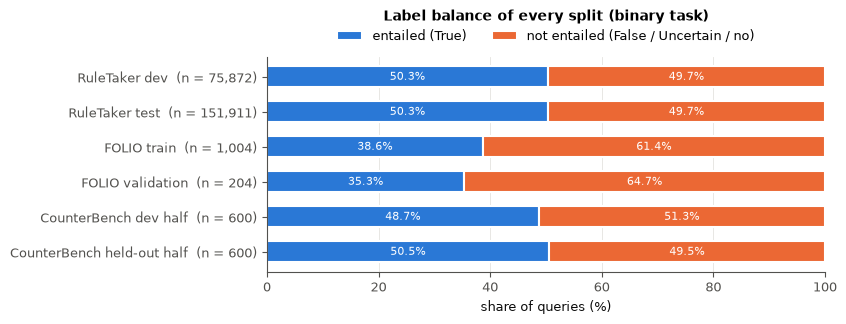

In [15]:
if CONFIG['RUN_EXPERIMENTS']:
    splits = [
        ('RuleTaker dev', RT_DEV),
        ('RuleTaker test', RT_TEST),
        ('FOLIO train', FOLIO_TRAIN),
        ('FOLIO validation', FOLIO_VAL),
        ('CounterBench dev half', CB_DEV),
        ('CounterBench held-out half', CB_TEST),
    ]
    STATS = {
        'splits': {name: {'n': len(rows), 'true': sum(r['label'] for r in rows)} for name, rows in splits}
    }

    fig, ax = plt.subplots(figsize=(7.2, 2.8))
    names = [f'{name}  (n = {len(rows):,})' for name, rows in splits][::-1]
    true_pct = [100 * STATS['splits'][name]['true'] / len(rows) for name, rows in splits][::-1]
    false_pct = [100 - p for p in true_pct]
    b1 = ax.barh(
        names, true_pct, color=BLUE, height=0.6, edgecolor='white', linewidth=1.5, label='entailed (True)'
    )
    b2 = ax.barh(
        names,
        false_pct,
        left=true_pct,
        color=ORANGE,
        height=0.6,
        edgecolor='white',
        linewidth=1.5,
        label='not entailed (False / Uncertain / no)',
    )
    for bars, values, lefts in ((b1, true_pct, [0] * len(true_pct)), (b2, false_pct, true_pct)):
        for bar, v, left in zip(bars, values, lefts):
            ax.text(
                left + v / 2,
                bar.get_y() + bar.get_height() / 2,
                f'{v:.1f}%',
                ha='center',
                va='center',
                color='white',
                fontsize=8,
            )
    ax.set_xlim(0, 100)
    ax.set_xlabel('share of queries (%)')
    ax.grid(axis='x')
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, 1.18), ncol=2)
    ax.set_title('Label balance of every split (binary task)', pad=26)
    save_figure(fig, 'fig_label_balance')

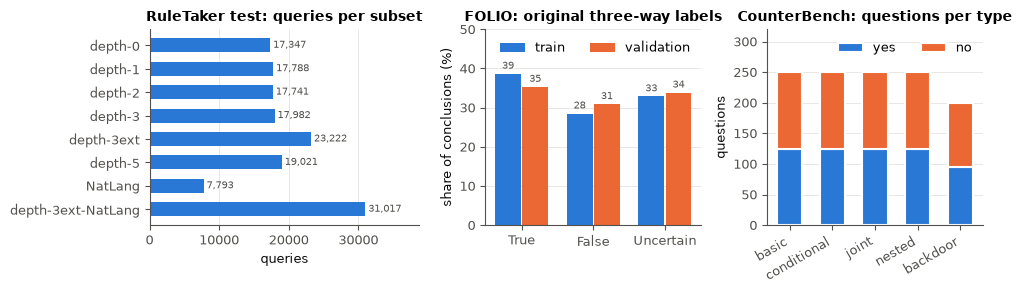

In [16]:
if CONFIG['RUN_EXPERIMENTS']:
    fig, axes = plt.subplots(1, 3, figsize=(10, 3.0), gridspec_kw={'width_ratios': [1.25, 1, 1]})

    configs = Counter(r['config'] for r in RT_TEST)
    order = sorted(configs, key=lambda c: (('NatLang' in c), c))
    bars = axes[0].barh(order[::-1], [configs[c] for c in order[::-1]], color=BLUE, height=0.6)
    axes[0].bar_label(
        bars, labels=[f'{configs[c]:,}' for c in order[::-1]], padding=2, color=INK_MUTED, fontsize=7
    )
    axes[0].set_title('RuleTaker test: queries per subset')
    axes[0].set_xlabel('queries')
    axes[0].grid(axis='x')
    axes[0].set_xlim(0, max(configs.values()) * 1.25)

    labels3 = ['True', 'False', 'Uncertain']
    x = range(len(labels3))
    for k, (name, rows, color) in enumerate(
        [('train', FOLIO_TRAIN, BLUE), ('validation', FOLIO_VAL, ORANGE)]
    ):
        counts = Counter('Uncertain' if r['raw_label'] == 'Unknown' else r['raw_label'] for r in rows)
        pct = [100 * counts[l] / len(rows) for l in labels3]
        bars = axes[1].bar([i + (k - 0.5) * 0.38 for i in x], pct, width=0.36, color=color, label=name)
        axes[1].bar_label(bars, fmt='%.0f', padding=2, color=INK_MUTED, fontsize=7)
    axes[1].set_xticks(list(x), labels3)
    axes[1].set_ylabel('share of conclusions (%)')
    axes[1].set_title('FOLIO: original three-way labels')
    axes[1].grid(axis='y')
    axes[1].set_ylim(0, 50)
    axes[1].legend(loc='upper right', ncol=2)

    types = ['basic', 'conditional', 'joint', 'nested', 'backdoor']
    yes = [sum(1 for r in CB_ALL if r['type'] == t and r['label']) for t in types]
    no = [sum(1 for r in CB_ALL if r['type'] == t and not r['label']) for t in types]
    axes[2].bar(types, yes, color=BLUE, width=0.6, edgecolor='white', linewidth=1.5, label='yes')
    axes[2].bar(types, no, bottom=yes, color=ORANGE, width=0.6, edgecolor='white', linewidth=1.5, label='no')
    axes[2].set_title('CounterBench: questions per type')
    axes[2].set_ylabel('questions')
    axes[2].grid(axis='y')
    axes[2].set_ylim(0, 320)
    axes[2].legend(loc='upper right', ncol=2)
    axes[2].tick_params(axis='x', rotation=30)
    for label in axes[2].get_xticklabels():
        label.set_horizontalalignment('right')
    fig.tight_layout()
    STATS['ruletaker_configs'] = dict(configs)
    STATS['folio_labels'] = {
        n: dict(Counter('Uncertain' if r['raw_label'] == 'Unknown' else r['raw_label'] for r in rows))
        for n, rows in [('train', FOLIO_TRAIN), ('validation', FOLIO_VAL)]
    }
    STATS['counterbench_types'] = {t: {'yes': a, 'no': b} for t, a, b in zip(types, yes, no)}
    save_figure(fig, 'fig_composition')

{'ruletaker': {'min': 2, 'median': 13, 'max': 25, 'n': 12483}, 'folio': {'min': 1, 'median': 5, 'max': 11, 'n': 413}, 'counterbench': {'min': 5, 'median': 7, 'max': 10, 'n': 810}}


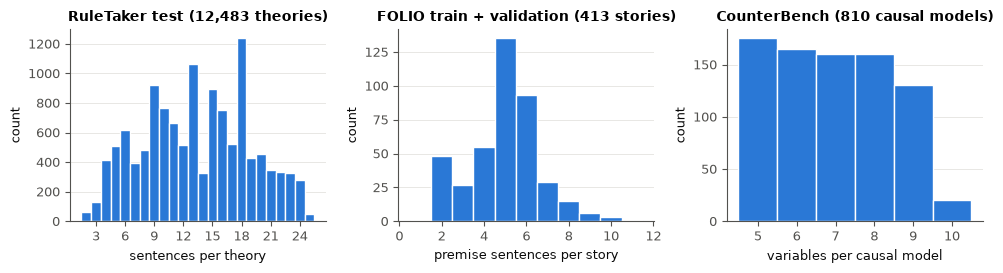

In [17]:
if CONFIG['RUN_EXPERIMENTS']:
    rt_sizes = [len(split_sentences(c)) for c in {r['context'] for r in RT_TEST}]
    folio_sizes = [len(split_sentences(c)) for c in {r['context'] for r in FOLIO_TRAIN + FOLIO_VAL}]
    cb_sizes = []
    for c in {r['context'] for r in CB_ALL}:
        scm = SCM()
        scm.parse(c)
        cb_sizes.append(len(scm.vars))
    fig, axes = plt.subplots(1, 3, figsize=(10, 2.8))
    for ax, sizes, title, xlabel in [
        (axes[0], rt_sizes, f'RuleTaker test ({len(rt_sizes):,} theories)', 'sentences per theory'),
        (
            axes[1],
            folio_sizes,
            f'FOLIO train + validation ({len(folio_sizes)} stories)',
            'premise sentences per story',
        ),
        (axes[2], cb_sizes, f'CounterBench ({len(cb_sizes)} causal models)', 'variables per causal model'),
    ]:
        bins = range(min(sizes), max(sizes) + 2)
        ax.hist(sizes, bins=bins, color=BLUE, edgecolor='white', linewidth=1.0, align='left')
        ax.set_title(title)
        ax.set_xlabel(xlabel)
        ax.set_ylabel('count')
        ax.grid(axis='y')
        ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
    fig.tight_layout()
    STATS['kb_size'] = {
        name: {'min': min(v), 'median': sorted(v)[len(v) // 2], 'max': max(v), 'n': len(v)}
        for name, v in [('ruletaker', rt_sizes), ('folio', folio_sizes), ('counterbench', cb_sizes)]
    }
    print(STATS['kb_size'])
    save_figure(fig, 'fig_kb_size')

### 3.3 Evaluation helper
Inference time covers parsing + reasoning for every query (KB compilation included); data loading is excluded.
Everything remembered from earlier inputs is forgotten (`clear_caches()`) before each timed run.

In [18]:
def clear_caches():
    """Forget everything learned from earlier inputs, so each timed run starts cold."""
    STORE.clear()
    HORN.cache.clear()
    LEX.cache = dict(IRREGULAR)
    if TRANSLATOR is not None:
        TRANSLATOR.cache.clear()


def evaluate(rows, name, use_fol=True, cwa=True, group=None, verbose=True):
    clear_caches()
    preds, engines, correct = [], Counter(), 0
    groups = defaultdict(lambda: [0, 0])
    t0 = time.perf_counter()
    for r in rows:
        ans, info = predict(
            r['context'],
            r['statement'],
            r['context_fol'] if use_fol else None,
            r['statement_fol'] if use_fol else None,
            cwa=cwa,
        )
        preds.append(ans)
        engines[info['engine']] += 1
        if r['label'] is not None:
            ok = ans == r['label']
            correct += ok
            if group:
                g = groups[r.get(group, '')]
                g[0] += ok
                g[1] += 1
    dt = time.perf_counter() - t0
    acc = 100 * correct / len(rows) if rows else 0.0
    if verbose:
        print(
            f'{name:45s} acc = {acc:6.2f}%   n = {len(rows):6d}   time = {dt:7.2f}s   ({1000 * dt / max(1, len(rows)):.3f} ms/query)'
        )
        print('    engines:', dict(engines))
        if group:
            print(
                '    ' + '  '.join(f'{k}: {100 * a / b:.1f}% ({b})' for k, (a, b) in sorted(groups.items()))
            )
        for problem, count in sorted(STORE.stats.items()):
            print(f'    {problem}: {count}')
    return {
        'name': name,
        'acc': acc,
        'n': len(rows),
        'time': dt,
        'preds': preds,
        'engines': engines,
        'groups': {k: 100 * a / b for k, (a, b) in groups.items()},
    }


RESULTS = {}

### 3.4 RuleTaker: closed vs. open world, forward vs. backward chaining

Development decisions (grammar coverage, CWA) were made on the **dev** split only; the **test** split is reported.

In [19]:
if CONFIG['RUN_EXPERIMENTS']:
    RESULTS['rt_dev_cwa'] = evaluate(RT_DEV, 'RuleTaker dev  (CWA, forward chaining)', group='config')
    RESULTS['rt_dev_owa'] = evaluate(
        RT_DEV, 'RuleTaker dev  (OWA, forward chaining)', cwa=False, group='config'
    )
    RESULTS['rt_test'] = evaluate(RT_TEST, 'RuleTaker test (CWA, forward chaining)', group='config')

RuleTaker dev  (CWA, forward chaining)        acc =  99.98%   n =  75872   time =    1.77s   (0.023 ms/query)
    engines: {'horn-forward-chaining': 75872}
    NatLang: 100.0% (3899)  depth-0: 100.0% (8718)  depth-1: 100.0% (8870)  depth-2: 100.0% (8906)  depth-3: 100.0% (8896)  depth-3ext: 100.0% (11587)  depth-3ext-NatLang: 100.0% (15510)  depth-5: 99.9% (9486)


RuleTaker dev  (OWA, forward chaining)        acc =  74.70%   n =  75872   time =    1.82s   (0.024 ms/query)
    engines: {'horn-forward-chaining': 75872}
    NatLang: 75.6% (3899)  depth-0: 77.8% (8718)  depth-1: 74.7% (8870)  depth-2: 73.1% (8906)  depth-3: 73.7% (8896)  depth-3ext: 74.0% (11587)  depth-3ext-NatLang: 74.4% (15510)  depth-5: 75.3% (9486)


RuleTaker test (CWA, forward chaining)        acc =  99.97%   n = 151911   time =    3.40s   (0.022 ms/query)
    engines: {'horn-forward-chaining': 151911}
    NatLang: 100.0% (7793)  depth-0: 100.0% (17347)  depth-1: 100.0% (17788)  depth-2: 100.0% (17741)  depth-3: 99.9% (17982)  depth-3ext: 100.0% (23222)  depth-3ext-NatLang: 100.0% (31017)  depth-5: 99.9% (19021)


#### Backward chaining, for comparison
Goal-driven SLD resolution with negation as failure over the same Horn representation. It is **not** used by the
system's router; it exists to compare answers and running time with forward chaining.

In [20]:
class BackwardChainer:
    def __init__(self, facts, rules, max_depth=40):
        self.facts = set(facts)
        self.rules = rules
        self.by_head = defaultdict(list)
        for r in rules:
            self.by_head[(r.head[0], r.head[1])].append(r)
        self.domain = sorted(
            {a for l in facts for a in l[2]}
            | {a for r in rules for l in r.body + [r.head] for a in l[2] if not is_var(a)}
        )
        self.memo = {}
        self.max_depth = max_depth
        self.calls = 0

    def prove(self, lit, stack=frozenset()):
        self.calls += 1
        pos, p, args = lit
        if not pos:  # negation as failure (stratified programs)
            if lit in self.facts:
                return True
            return not self.prove((True, p, args), stack)
        if lit in self.facts:
            return True
        if lit in self.memo:
            return self.memo[lit]
        if lit in stack or len(stack) > self.max_depth:
            return False
        stack = stack | {lit}
        result = False
        for r in self.by_head[(True, p)]:
            theta = unify_args(r.head[2], args, {})
            if theta is None:
                continue
            if self.solve(sorted(r.body, key=lambda l: not l[0]), theta, stack):
                result = True
                break
        if result or not stack - {lit}:  # cache only answers not cut by loop detection
            self.memo[lit] = result
        return result

    def solve(self, body, theta, stack):
        if not body:
            return True
        pos, p, args = body[0]
        free = [a for a in dict.fromkeys(args) if is_var(a) and a not in theta]
        for combo in itertools.product(self.domain, repeat=len(free)):
            t = dict(theta)
            t.update(zip(free, combo))
            if self.prove((pos, p, subst_args(args, t)), stack) and self.solve(body[1:], t, stack):
                return True
        return False


# PDF example
facts, rules, _ = parse_horn_kb(
    'Bob is young. Bob is kind. If someone is young, then they are smart. '
    'If someone is smart and kind, then they are successful.'
)
kb = HornKB(facts, rules)
q = parse_horn_query('Bob is successful.')
print('forward chaining :', kb.query(q))
print('backward chaining:', BackwardChainer(facts, rules).prove(q[0]))
print('\n'.join(kb.trace(q[0])))

forward chaining : True
backward chaining: True
Successful(Bob)   [by rule: If someone is smart and kind, then they are successful.]
  Smart(Bob)   [by rule: If someone is young, then they are smart.]
    Young(Bob)   [given fact]
  Kind(Bob)   [given fact]


In [21]:
if CONFIG['RUN_EXPERIMENTS']:

    def eval_backward(rows, name):
        t0, correct, n = time.perf_counter(), 0, 0
        cache = {}
        for r in rows:
            if r['context'] not in cache:
                f, ru, failed = parse_horn_kb(r['context'])
                cache[r['context']] = BackwardChainer(f, ru) if not failed else None
            bc = cache[r['context']]
            try:
                q = parse_horn_query(r['statement'])
            except ValueError:
                q = None
            ans = bc is not None and q is not None and all(bc.prove(l) for l in q)
            correct += ans == r['label']
            n += 1
        dt = time.perf_counter() - t0
        print(f'{name:45s} acc = {100 * correct / n:6.2f}%   n = {n:6d}   time = {dt:7.2f}s')
        return {'acc': 100 * correct / n, 'time': dt, 'n': n}

    sample = random.Random(1).sample(RT_TEST, min(20000, len(RT_TEST)))
    RESULTS['rt_fc_sample'] = evaluate(sample, 'RuleTaker test sample: forward chaining', verbose=True)
    RESULTS['rt_bc_sample'] = eval_backward(sample, 'RuleTaker test sample: backward chaining')

RuleTaker test sample: forward chaining       acc =  99.98%   n =  20000   time =    1.77s   (0.089 ms/query)
    engines: {'horn-forward-chaining': 20000}


RuleTaker test sample: backward chaining      acc = 100.00%   n =  20000   time =    0.60s


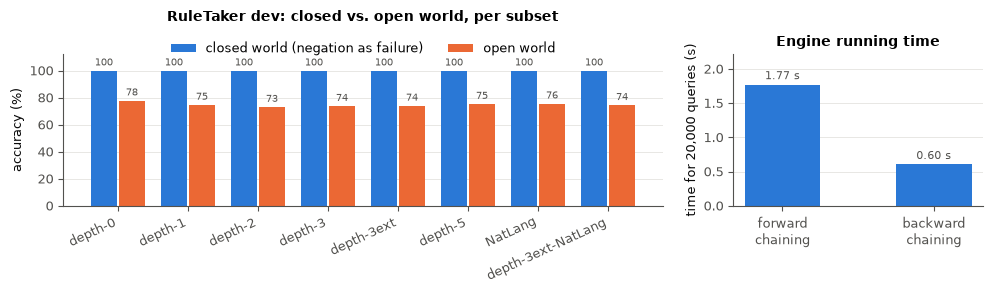

In [22]:
if CONFIG['RUN_EXPERIMENTS']:
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.0), gridspec_kw={'width_ratios': [2.4, 1]})
    cfgs = sorted(RESULTS['rt_dev_cwa']['groups'], key=lambda c: (('NatLang' in c), c))
    xs = range(len(cfgs))
    for k, (key, name, color) in enumerate(
        [('rt_dev_cwa', 'closed world (negation as failure)', BLUE), ('rt_dev_owa', 'open world', ORANGE)]
    ):
        vals = [RESULTS[key]['groups'][c] for c in cfgs]
        bars = axes[0].bar([i + (k - 0.5) * 0.4 for i in xs], vals, width=0.38, color=color, label=name)
        axes[0].bar_label(bars, fmt='%.0f', padding=2, color=INK_MUTED, fontsize=7)
    axes[0].set_xticks(list(xs), cfgs, rotation=25, ha='right')
    axes[0].set_ylim(0, 112)
    axes[0].set_ylabel('accuracy (%)')
    axes[0].grid(axis='y')
    axes[0].legend(loc='upper center', bbox_to_anchor=(0.5, 1.16), ncol=2)
    axes[0].set_title('RuleTaker dev: closed vs. open world, per subset', pad=24)

    times = [RESULTS['rt_fc_sample']['time'], RESULTS['rt_bc_sample']['time']]
    bars = axes[1].bar(['forward\nchaining', 'backward\nchaining'], times, color=[BLUE, BLUE], width=0.5)
    axes[1].bar_label(bars, fmt='%.2f s', padding=2, color=INK_MUTED, fontsize=8)
    axes[1].set_ylabel('time for 20,000 queries (s)')
    axes[1].set_title('Engine running time')
    axes[1].grid(axis='y')
    axes[1].set_ylim(0, max(times) * 1.25)
    fig.tight_layout()
    save_figure(fig, 'fig_ruletaker_ablation')

### 3.5 FOLIO: natural language vs. gold FOL annotations
FOLIO conclusions are labelled True / False / Uncertain; only True counts as entailed. The NL translator was developed
on the **train** split (which has no conclusion-FOL annotations) and is reported on **validation**. The ⊕ reading of
*either … or* was chosen on train.

In [23]:
if CONFIG['RUN_EXPERIMENTS']:
    RESULTS['folio_train_nl'] = evaluate(
        FOLIO_TRAIN, 'FOLIO train      (NL → FOL → resolution)', use_fol=False
    )
    RESULTS['folio_val_nl'] = evaluate(FOLIO_VAL, 'FOLIO validation (NL → FOL → resolution)', use_fol=False)
    RESULTS['folio_val_fol'] = evaluate(FOLIO_VAL, 'FOLIO validation (gold FOL → resolution)', use_fol=True)
    base = 100 * sum(not r['label'] for r in FOLIO_VAL) / len(FOLIO_VAL)
    print(f'FOLIO validation majority baseline (always False): {base:.2f}%')

FOLIO train      (NL → FOL → resolution)      acc =  65.14%   n =   1004   time =    5.35s   (5.324 ms/query)
    engines: {'nl-fol-resolution': 996, 'horn-forward-chaining': 8}
    Horn grammar: KBs not covered (sent to NL→FOL): 332
    NL→FOL: conclusions not translated (answered False): 28
    NL→FOL: premise sentences not translated: 83


FOLIO validation (NL → FOL → resolution)      acc =  66.18%   n =    204   time =    1.28s   (6.294 ms/query)
    engines: {'nl-fol-resolution': 204}
    Horn grammar: KBs not covered (sent to NL→FOL): 73
    NL→FOL: conclusions not translated (answered False): 6
    NL→FOL: premise sentences not translated: 17


FOLIO validation (gold FOL → resolution)      acc =  98.04%   n =    204   time =    0.32s   (1.566 ms/query)
    engines: {'fol-resolution': 204}
    FOL: unparsable premise formulas (skipped): 2
FOLIO validation majority baseline (always False): 64.71%


#### FOLIO ablations (all decided on the train split)
* reading *either … or* as exclusive (⊕) or inclusive (∨) disjunction;
* discarding resolvents subsumed by a unit clause, on or off;
* the resolution step budget: how many resolution steps proofs actually need, measured with a much larger budget.

In [24]:
if CONFIG['RUN_EXPERIMENTS']:
    TRANSLATOR.xor_either = False
    RESULTS['folio_train_nl_or'] = evaluate(FOLIO_TRAIN, 'FOLIO train, "either…or" read as ∨', use_fol=False)
    TRANSLATOR.xor_either = True

    CONFIG['RES_UNIT_SUBSUMPTION'] = False
    RESULTS['folio_train_nl_nosub'] = evaluate(FOLIO_TRAIN, 'FOLIO train, no unit subsumption', use_fol=False)
    RESULTS['folio_val_fol_nosub'] = evaluate(
        FOLIO_VAL, 'FOLIO val gold FOL, no unit subsumption', use_fol=True
    )
    CONFIG['RES_UNIT_SUBSUMPTION'] = True

    # resolution steps with a 10x larger budget
    saved_budget = CONFIG['RES_MAX_STEPS'], CONFIG['RES_TIME_LIMIT']
    CONFIG['RES_MAX_STEPS'], CONFIG['RES_TIME_LIMIT'] = 20000, 10.0
    clear_caches()
    proved, not_proved = [], []
    for r in FOLIO_TRAIN:
        ans, info = predict(r['context'], r['statement'])
        if 'steps' not in info:
            continue
        found = ans or info.get('reason') in ('tautological goal', 'inconsistent premises')
        (proved if found else not_proved).append(max(1, info['steps']))
    CONFIG['RES_MAX_STEPS'], CONFIG['RES_TIME_LIMIT'] = saved_budget
    RESULTS['folio_train_steps'] = {'proved': proved, 'not_proved': not_proved}
    print(
        f'refutations found: {len(proved)}, max steps {max(proved)}; '
        f'searches without refutation: {len(not_proved)}, '
        f'{sum(s >= 2000 for s in not_proved)} of them needed >= 2000 steps'
    )

FOLIO train, "either…or" read as ∨            acc =  64.94%   n =   1004   time =    4.48s   (4.464 ms/query)
    engines: {'nl-fol-resolution': 996, 'horn-forward-chaining': 8}
    Horn grammar: KBs not covered (sent to NL→FOL): 332
    NL→FOL: conclusions not translated (answered False): 28
    NL→FOL: premise sentences not translated: 83


FOLIO train, no unit subsumption              acc =  65.14%   n =   1004   time =    4.76s   (4.740 ms/query)
    engines: {'nl-fol-resolution': 996, 'horn-forward-chaining': 8}
    Horn grammar: KBs not covered (sent to NL→FOL): 332
    NL→FOL: conclusions not translated (answered False): 28
    NL→FOL: premise sentences not translated: 83


FOLIO val gold FOL, no unit subsumption       acc =  98.04%   n =    204   time =    0.52s   (2.539 ms/query)
    engines: {'fol-resolution': 204}
    FOL: unparsable premise formulas (skipped): 2


refutations found: 120, max steps 26; searches without refutation: 848, 9 of them needed >= 2000 steps


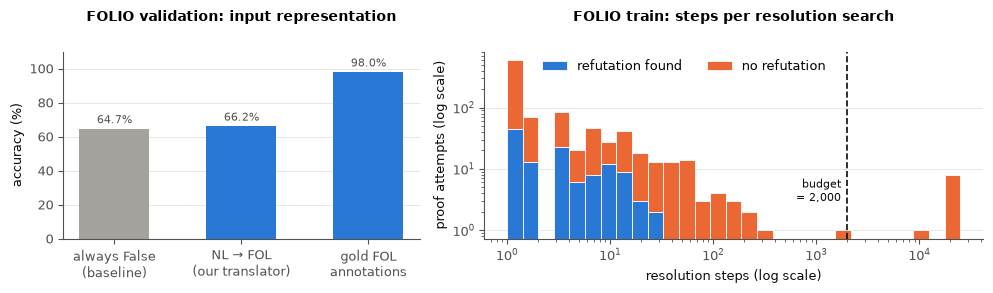

In [25]:
if CONFIG['RUN_EXPERIMENTS']:
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.0), gridspec_kw={'width_ratios': [1, 1.4]})
    base = 100 * sum(not r['label'] for r in FOLIO_VAL) / len(FOLIO_VAL)
    names = ['always False\n(baseline)', 'NL → FOL\n(our translator)', 'gold FOL\nannotations']
    vals = [base, RESULTS['folio_val_nl']['acc'], RESULTS['folio_val_fol']['acc']]
    bars = axes[0].bar(names, vals, color=[NEUTRAL, BLUE, BLUE], width=0.55)
    axes[0].bar_label(bars, fmt='%.1f%%', padding=2, color=INK_MUTED, fontsize=8)
    axes[0].set_ylim(0, 110)
    axes[0].set_ylabel('accuracy (%)')
    axes[0].set_title('FOLIO validation: input representation', pad=22)
    axes[0].grid(axis='y')

    import numpy as np

    bins = np.logspace(0, np.log10(25000), 30)  # the larger budget caps searches just above 20,000
    axes[1].hist(
        [proved, not_proved],
        bins=bins,
        color=[BLUE, ORANGE],
        edgecolor='white',
        linewidth=0.6,
        label=['refutation found', 'no refutation'],
        stacked=True,
    )
    axes[1].set_xscale('log')
    axes[1].set_yscale('log')
    axes[1].axvline(2000, color=INK, linewidth=1.2, linestyle='--')
    axes[1].text(2000 / 1.15, 3, 'budget\n= 2,000', color=INK, fontsize=8, ha='right')
    axes[1].set_xlabel('resolution steps (log scale)')
    axes[1].set_ylabel('proof attempts (log scale)')
    axes[1].grid(axis='y')
    axes[1].legend(loc='upper center', ncol=2, bbox_to_anchor=(0.4, 1.02))
    axes[1].set_title('FOLIO train: steps per resolution search', pad=22)
    fig.tight_layout()
    save_figure(fig, 'fig_folio')

### 3.6 CounterBench: counterfactual semantics
The reading of *nested* questions was chosen on the dev half (sequential interventions vs. holding the mediator at
its value under the opposite treatment); results are reported on the held-out half.

In [26]:
if CONFIG['RUN_EXPERIMENTS']:

    def eval_cb_mode(rows, mode):
        ok = sum(
            causal_predict(r['context'], r['statement'], nested_mode=mode)[0] == r['label']
            for r in rows
            if r['type'] == 'nested'
        )
        return 100 * ok / sum(r['type'] == 'nested' for r in rows)

    RESULTS['cb_nested_modes'] = {mode: eval_cb_mode(CB_DEV, mode) for mode in ('sequential', 'mediator')}
    for mode, acc in RESULTS['cb_nested_modes'].items():
        print(f'nested questions, dev half, {mode:10s}: {acc:.1f}%')
    RESULTS['cb_dev'] = evaluate(CB_DEV, 'CounterBench dev half', group='type')
    RESULTS['cb_test'] = evaluate(CB_TEST, 'CounterBench held-out half', group='type')

nested questions, dev half, sequential: 95.2%
nested questions, dev half, mediator  : 36.3%
CounterBench dev half                         acc =  94.33%   n =    600   time =    0.05s   (0.080 ms/query)
    engines: {'scm-counterfactual': 600}
    backdoor: 91.4% (93)  basic: 100.0% (131)  conditional: 90.1% (121)  joint: 93.9% (131)  nested: 95.2% (124)
CounterBench held-out half                    acc =  94.00%   n =    600   time =    0.05s   (0.080 ms/query)
    engines: {'scm-counterfactual': 600}
    backdoor: 88.8% (107)  basic: 100.0% (119)  conditional: 86.0% (129)  joint: 98.3% (119)  nested: 96.8% (126)


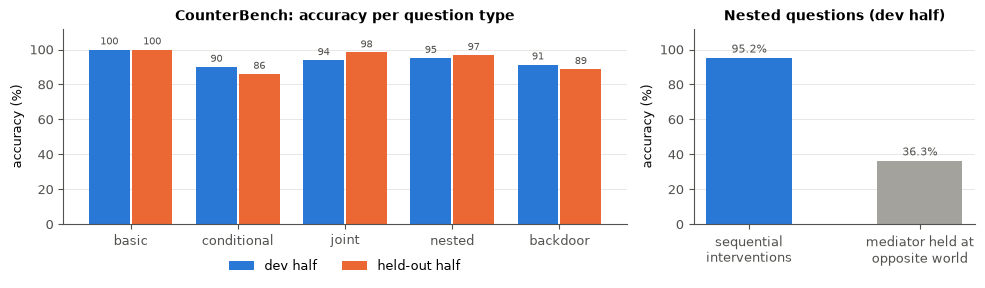

In [27]:
if CONFIG['RUN_EXPERIMENTS']:
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.0), gridspec_kw={'width_ratios': [2, 1]})
    types = ['basic', 'conditional', 'joint', 'nested', 'backdoor']
    xs = range(len(types))
    for k, (key, name, color) in enumerate(
        [('cb_dev', 'dev half', BLUE), ('cb_test', 'held-out half', ORANGE)]
    ):
        vals = [RESULTS[key]['groups'][t] for t in types]
        bars = axes[0].bar([i + (k - 0.5) * 0.4 for i in xs], vals, width=0.38, color=color, label=name)
        axes[0].bar_label(bars, fmt='%.0f', padding=2, color=INK_MUTED, fontsize=7)
    axes[0].set_xticks(list(xs), types)
    axes[0].set_ylim(0, 112)
    axes[0].set_ylabel('accuracy (%)')
    axes[0].set_title('CounterBench: accuracy per question type')
    axes[0].grid(axis='y')
    axes[0].legend(loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=2)

    modes = RESULTS['cb_nested_modes']
    bars = axes[1].bar(
        ['sequential\ninterventions', 'mediator held at\nopposite world'],
        [modes['sequential'], modes['mediator']],
        color=[BLUE, NEUTRAL],
        width=0.5,
    )
    axes[1].bar_label(bars, fmt='%.1f%%', padding=2, color=INK_MUTED, fontsize=8)
    axes[1].set_ylim(0, 112)
    axes[1].set_ylabel('accuracy (%)')
    axes[1].set_title('Nested questions (dev half)')
    axes[1].grid(axis='y')
    fig.tight_layout()
    save_figure(fig, 'fig_counterbench')

# Part 4 — Reasoning traces

Example proofs produced by each engine.

In [28]:
if CONFIG['RUN_EXPERIMENTS']:

    def show_horn_trace(row):
        ans, info = predict(row['context'], row['statement'])
        print('CONTEXT  :', row['context'][:400] + ('…' if len(row['context']) > 400 else ''))
        print('QUERY    :', row['statement'], '→', [lit_str(l) for l in info['query']])
        print('PREDICTED:', ans, '| GOLD:', row['label'])
        for l in info['query']:
            print('\n'.join('   ' + s for s in info['kb'].trace(l)))
        print()

    def trace_len(row):
        ans, info = predict(row['context'], row['statement'])
        return len(info['kb'].trace(info['query'][0])) if ans and 'kb' in info else 0

    deep = [
        r for r in RT_TEST if r.get('config') == 'depth-3' and r['label'] and ' not ' not in r['statement']
    ][:300]
    show_horn_trace(max(deep, key=trace_len))
    neg = [r for r in RT_TEST if r.get('config') == 'depth-2' and r['label'] and ' not ' in r['statement']]
    show_horn_trace(neg[0])

CONTEXT  : The cow is round. The cow likes the mouse. The mouse eats the cow. If someone does not like the mouse then they visit the cow. If the cow eats the mouse and the mouse eats the cow then the mouse likes the cow. If someone eats the mouse and the mouse visits the cow then the cow visits the mouse. If the cow is round and the cow visits the mouse then the cow is young. If the cow is not nice then the …
QUERY    : The cow is young. → ['Young(Cow)']
PREDICTED: True | GOLD: True
   Young(Cow)   [by rule: If the cow is round and the cow visits the mouse then the cow is young.]
     Round(Cow)   [given fact]
     Visit(Cow, Mouse)   [by rule: If someone eats the mouse and the mouse visits the cow then the cow visits the mouse.]
       Eat(Cow, Mouse)   [by rule: If the cow is not nice then the cow eats the mouse.]
         ¬Nice(Cow)   [negation as failure: Nice(Cow) is not derivable]
       Visit(Mouse, Cow)   [by rule: If someone does not like the mouse then they visit the cow.]
  

In [29]:
if CONFIG['RUN_EXPERIMENTS']:
    r = FOLIO_VAL[0]
    print('PREMISES (FOL):')
    print('   ' + '\n   '.join(fol_lines(r['context_fol'])))
    print('CONCLUSION   :', r['statement_fol'], '| GOLD:', r['label'])
    ans, info = predict_fol(r['context_fol'], r['statement_fol'])
    print('PREDICTED    :', ans, f"({info.get('steps')} resolution steps)")
    print('\n'.join('   ' + l for l in (info.get('proof') or ['no refutation found (not entailed)'])))
    print()
    for r in FOLIO_VAL:
        ans, info = nl_fol_predict(r['context'], r['statement'])
        if ans and r['label']:
            print('NL PREMISES  :')
            print('   ' + '\n   '.join(split_sentences(r['context'])))
            print('NL CONCLUSION:', r['statement'])
            print('TRANSLATED GOAL:', info['goal'])
            print('\n'.join('   ' + l for l in info['proof']))
            break

PREMISES (FOL):
   ∀x (TalentShows(x) → Engaged(x))
   ∀x (TalentShows(x) ∨ Inactive(x))
   ∀x (Chaperone(x) → ¬Students(x))
   ∀x (Inactive(x) → Chaperone(x))
   ∀x (AcademicCareer(x) → Students(x))
   (Engaged(bonnie) ∧ Students(bonnie)) ⊕ (¬Engaged(bonnie) ∧ ¬Students(bonnie))
CONCLUSION   : Engaged(bonnie) | GOLD: False
PREDICTED    : False (7 resolution steps)
   no refutation found (not entailed)

NL PREMISES  :
   There are six types of wild turkeys: Eastern wild turkey, Osceola wild turkey, Gould’s wild turkey, Merriam’s wild turkey, Rio Grande wild turkey, and Ocellated wild turkey.
   Tom is not an Eastern wild turkey.
   Tom is not an Osceola wild turkey.
   Tom is also not a Gould's wild turkey, or a Merriam's wild turkey, or a Rio Grande wild turkey.
   Tom is a wild turkey.
NL CONCLUSION: Tom is an Ocellated wild turkey.
TRANSLATED GOAL: ('atom', 'wild_turkey', ('tom',))
   □ (empty clause)   ⇐ resolve [¬WildTurkey(Tom)] with [WildTurkey(Tom)]


In [30]:
if CONFIG['RUN_EXPERIMENTS']:
    r = next(x for x in CB_TEST if x['type'] == 'conditional')
    ans, scm, p = causal_predict(r['context'], r['statement'])
    print('CONTEXT :', r['context'])
    print('QUESTION:', r['statement'])
    for v in scm.topo():
        if v in scm.eq:
            print(
                f'   {v} := '
                + ' ∨ '.join(
                    ('' if pos else '¬') + '(' + f' {op} '.join(('¬' if n else '') + u for n, u in ls) + ')'
                    for (op, ls), pos in scm.eq[v]
                )
            )
        else:
            print(f'   {v} ~ Bernoulli({scm.prior.get(v, 0.5)})  (exogenous)')
    print(f'P(query) = {p:.3f} → answer {ans} | GOLD: {r["label"]}')

CONTEXT : We know that Ziklo causes not Blaf, Blaf and Trune together cause Vork, Vork causes Lumbo. We observed Trune
QUESTION: Would Lumbo occur if not Ziklo instead of Ziklo?
   ziklo ~ Bernoulli(0.5)  (exogenous)
   blaf := ¬(ziklo)
   trune ~ Bernoulli(0.5)  (exogenous)
   vork := (blaf and trune)
   lumbo := (vork)
P(query) = 1.000 → answer True | GOLD: True


# Final evaluation, inference time and `submission.csv`

**Efficiency measures** (inference on the 152,715-query public set went from 9.87 s to about 3.7 s, measured from a
cold start; accuracy unchanged):
* each knowledge base is classified and compiled once (`ContextStore`) and shared by all queries about it;
* the Horn parser and the FOL translator remember sentences they have already parsed (knowledge bases share many);
* forward chaining uses pre-compiled rules, direct set-membership tests for bound literals, and semi-naive rule
  triggering (a rule is re-fired only when one of its body predicates gained new facts);
* FOLIO: spaCy runs once, batched, per new sentence; premise clauses are converted to CNF once per story;
* resolution uses a **deterministic step budget** (2,000 resolvents; proofs on FOLIO train need at most 26) and
  skips clause pairs without complementary predicates, so results do not depend on machine speed.

If `CONFIG['TEST_PATH']` exists, predictions are produced for that file; otherwise the combined public evaluation set
(RuleTaker test + FOLIO validation + CounterBench held-out half) is used. The file contains `id,label`.

In [31]:
def make_submission(rows, out_path):
    clear_caches()
    t0 = time.perf_counter()
    preds = [predict(r['context'], r['statement'], r['context_fol'], r['statement_fol'])[0] for r in rows]
    dt = time.perf_counter() - t0
    pd.DataFrame({'id': [r['id'] for r in rows], 'label': ['True' if p else 'False' for p in preds]}).to_csv(
        out_path, index=False
    )
    labelled = [(p, r['label']) for p, r in zip(preds, rows) if r['label'] is not None]
    acc = 100 * sum(p == g for p, g in labelled) / len(labelled) if labelled else None
    return preds, acc, dt


if os.path.exists(CONFIG['TEST_PATH']):
    EVAL_ROWS = load_test_file(CONFIG['TEST_PATH'])
    print(f"Using test file {CONFIG['TEST_PATH']} ({len(EVAL_ROWS)} rows)")
elif CONFIG['RUN_EXPERIMENTS']:
    EVAL_ROWS = RT_TEST + FOLIO_VAL + CB_TEST
    print(f"{CONFIG['TEST_PATH']} not found: using the public evaluation set ({len(EVAL_ROWS)} rows)")
else:
    raise FileNotFoundError(
        f"{CONFIG['TEST_PATH']} not found; set CONFIG['TEST_PATH'] or RUN_EXPERIMENTS=True"
    )

preds, acc, dt = make_submission(EVAL_ROWS, CONFIG['OUT_PATH'])
RESULTS['final'] = {'acc': acc, 'time': dt, 'n': len(preds)}
print(f"wrote {CONFIG['OUT_PATH']} with {len(preds)} predictions")
print('=' * 70)
print(
    f'FINAL ACCURACY      : {acc:.2f}%'
    if acc is not None
    else 'FINAL ACCURACY      : n/a (test file has no labels)'
)
print(f'TOTAL INFERENCE TIME: {dt:.2f} s  ({1000 * dt / len(preds):.3f} ms/query)')
print('=' * 70)

test.csv not found: using the public evaluation set (152715 rows)


wrote submission.csv with 152715 predictions
FINAL ACCURACY      : 99.94%
TOTAL INFERENCE TIME: 3.60 s  (0.024 ms/query)


In [32]:
if CONFIG['RUN_EXPERIMENTS']:
    summary = pd.DataFrame(
        [
            [
                'RuleTaker test (CWA)',
                RESULTS['rt_test']['n'],
                RESULTS['rt_test']['acc'],
                RESULTS['rt_test']['time'],
            ],
            [
                'FOLIO validation, NL input',
                RESULTS['folio_val_nl']['n'],
                RESULTS['folio_val_nl']['acc'],
                RESULTS['folio_val_nl']['time'],
            ],
            [
                'FOLIO validation, gold FOL input',
                RESULTS['folio_val_fol']['n'],
                RESULTS['folio_val_fol']['acc'],
                RESULTS['folio_val_fol']['time'],
            ],
            [
                'CounterBench held-out half',
                RESULTS['cb_test']['n'],
                RESULTS['cb_test']['acc'],
                RESULTS['cb_test']['time'],
            ],
        ],
        columns=['dataset', 'n', 'accuracy %', 'time s'],
    ).round(2)
    print(summary.to_string(index=False))
    # keep the numbers behind every table and figure (used to write the report)
    saved = {}
    for key, value in RESULTS.items():
        saved[key] = {k: v for k, v in value.items() if k not in ('preds', 'engines')}
        if 'engines' in value:
            saved[key]['engines'] = dict(value['engines'])
    saved['stats'] = STATS
    with open(os.path.join(DATA_DIR, 'results.json'), 'w') as fh:
        json.dump(saved, fh, indent=1, default=str)

                         dataset      n  accuracy %  time s
            RuleTaker test (CWA) 151911       99.97    3.40
      FOLIO validation, NL input    204       66.18    1.28
FOLIO validation, gold FOL input    204       98.04    0.32
      CounterBench held-out half    600       94.00    0.05
